#Overview: Listening to Two Black Holes Collide (GW150914)

#What is this project about?

Imagine two huge black holes spinning around each other in space. They get closer and faster, and then they crash together. That crash shakes space itself, like a stone dropped in a pond makes ripples in the water. These ripples are called gravitational waves.

On September 14, 2015, two giant machines in the USA, one in Hanford and one in Livingston, felt one of these ripples. It was the first time humans ever detected gravitational waves. The event is called GW150914.

The ripple is incredibly tiny. It is much smaller than a proton, and it is buried inside a lot of machine noise.

#What does this notebook do?

This notebook takes the real data from those two machines and shows, step by step, how to find the hidden ripple:

Download the real data.
Clean the noise with a filter.
Zoom in on the crash and see the "chirp" (a wave that gets faster and taller, then stops).
Compare it with what Einstein's theory predicts.
Draw colorful pictures of the chirp over time.
Use a "matched filter" to prove the signal is really there.

#The main result

The chirp shows up in both detectors and matches the theory shape. The matched filter found the event with a signal-to-noise ratio of about 16.8, which is far above the background noise.

In [ ]:
!pip -q install gwpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.2/45.2 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.1/114.1 kB 3.2 MB/s eta 0:00:00


In [ ]:
from gwpy.timeseries import TimeSeries
import matplotlib.pyplot as plt

In [ ]:
event_time = 1126259462

h1 = TimeSeries.fetch_open_data(
    "H1",
    event_time - 16,
    event_time + 16,
    cache=False
)

l1 = TimeSeries.fetch_open_data(
    "L1",
    event_time - 16,
    event_time + 16,
    cache=False
)

In [ ]:
# Basic information about the data

print("========== Hanford (H1) ==========")
print(h1)

print("\n========== Livingston (L1) ==========")
print(l1)

print("\n========== Dataset Summary ==========")

print(f"Number of H1 samples : {len(h1):,}")
print(f"Number of L1 samples : {len(l1):,}")

print(f"\nSampling Rate : {h1.sample_rate}")

print(f"Time Interval (dt) : {h1.dt}")

print(f"Recording Duration : {h1.duration}")

print(f"Start Time : {h1.t0}")

print(f"End Time : {h1.span[1]}")

========== Hanford (H1) ==========
TimeSeries([2.17704028e-19, 2.08763900e-19, 2.39681183e-19, ...,
            3.55365541e-20, 6.33533516e-20, 7.58121195e-20],
           unit: dimensionless,
           dtype: float64,
           t0: 1126259446.0 s,
           dt: 0.000244140625 s,
           name: H1:Strain,
           channel: None)

========== Livingston (L1) ==========
TimeSeries([-1.04289994e-18, -1.03586274e-18, -9.89322445e-19,
            ..., -1.01767748e-18, -9.82876815e-19,
            -9.59276974e-19],
           unit: dimensionless,
           dtype: float64,
           t0: 1126259446.0 s,
           dt: 0.000244140625 s,
           name: L1:Strain,
           channel: None)

========== Dataset Summary ==========
Number of H1 samples : 131,072
Number of L1 samples : 131,072

Sampling Rate : 4096.0 Hz
Time Interval (dt) : 0.000244140625 s
Recording Duration : 32.0 s
Start Time : 1126259446.0 s
End Time : 1126259478.0


## Visualizing the Raw Gravitational Wave Signal

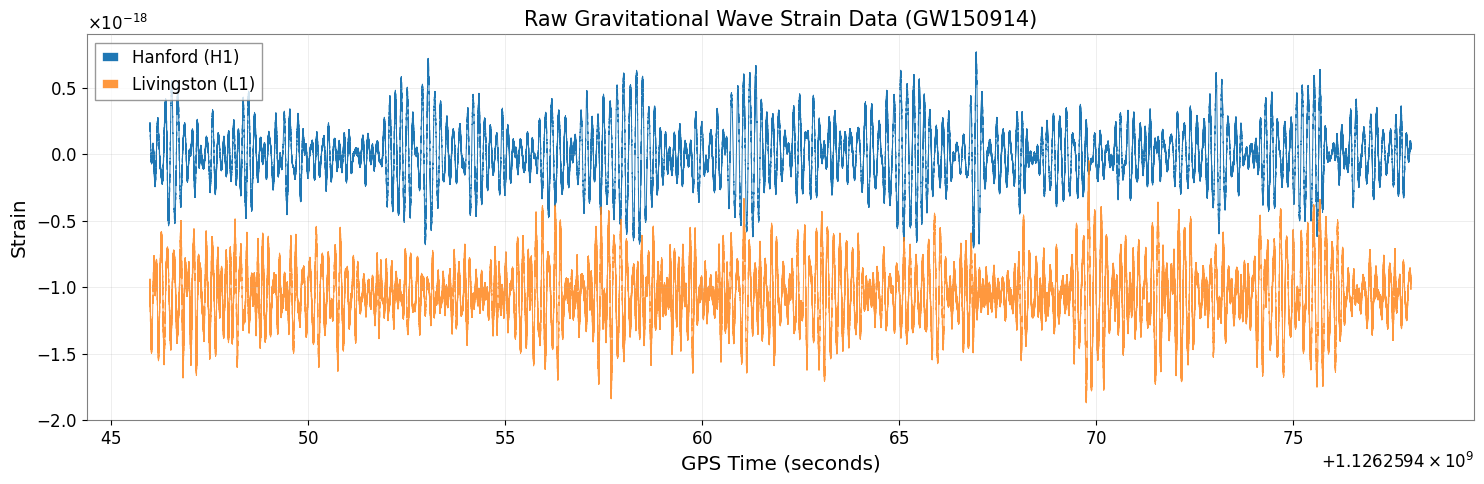

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(
    h1.times.value,
    h1.value,
    label="Hanford (H1)",
    linewidth=0.7
)

plt.plot(
    l1.times.value,
    l1.value,
    label="Livingston (L1)",
    linewidth=0.7,
    alpha=0.8
)

plt.title("Raw Gravitational Wave Strain Data (GW150914)", fontsize=15)

plt.xlabel("GPS Time (seconds)")
plt.ylabel("Strain")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [ ]:
# Apply a Band-Pass Filter

# Keep only frequencies between 30 Hz and 400 Hz
h1_filtered = h1.bandpass(30, 400)
l1_filtered = l1.bandpass(30, 400)

print("Filtering completed successfully!")


Filtering completed successfully!


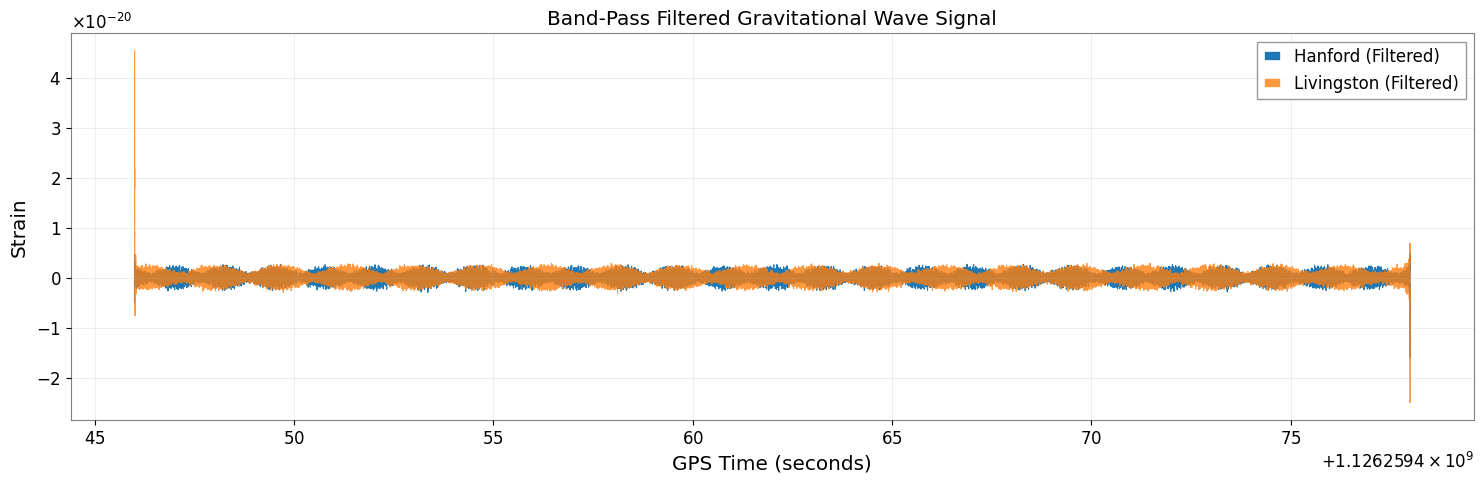

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(
    h1_filtered.times.value,
    h1_filtered.value,
    label="Hanford (Filtered)",
    linewidth=0.8
)

plt.plot(
    l1_filtered.times.value,
    l1_filtered.value,
    label="Livingston (Filtered)",
    linewidth=0.8,
    alpha=0.8
)

plt.title("Band-Pass Filtered Gravitational Wave Signal")

plt.xlabel("GPS Time (seconds)")
plt.ylabel("Strain")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# Zoom into the merger event

In [ ]:
event_time = 1126259462.4

h1_zoom = h1_filtered.crop(
    event_time - 0.2,
    event_time + 0.2
)

l1_zoom = l1_filtered.crop(
    event_time - 0.2,
    event_time + 0.2
)

print("H1 zoom samples:", len(h1_zoom))
print("L1 zoom samples:", len(l1_zoom))

H1 zoom samples: 1638
L1 zoom samples: 1638


## Plot the zoomed waveform

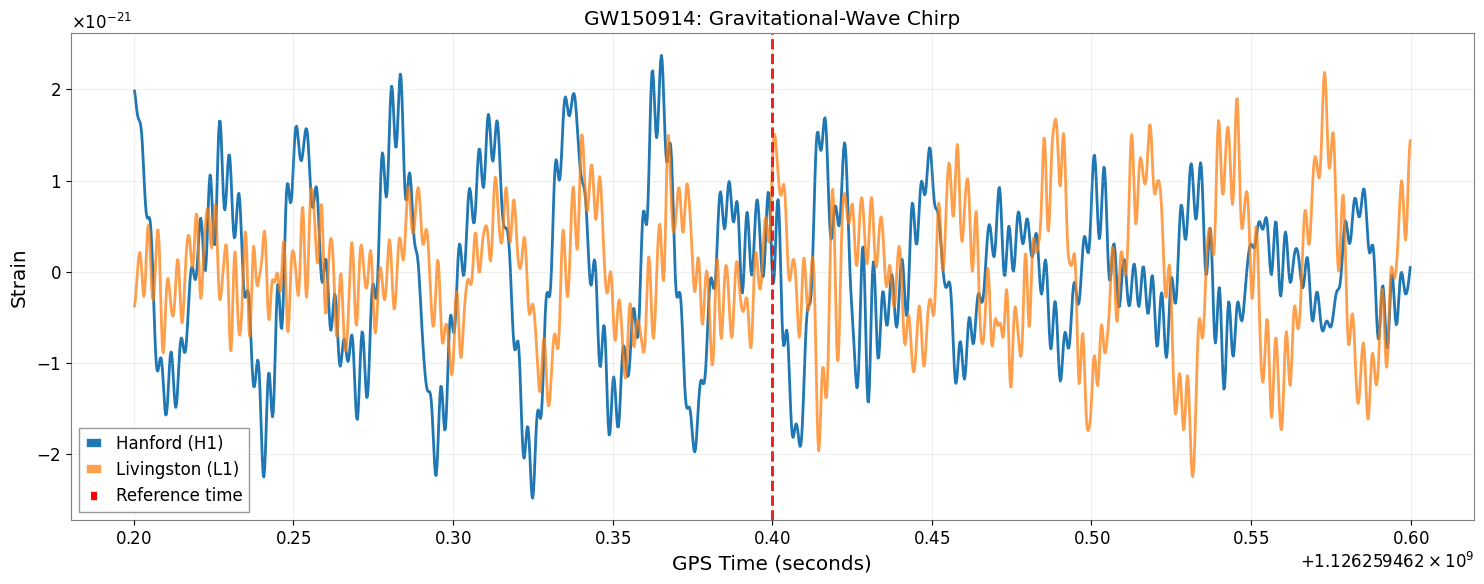

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    h1_zoom.times.value,
    h1_zoom.value,
    label="Hanford (H1)",
    linewidth=2
)

plt.plot(
    l1_zoom.times.value,
    l1_zoom.value,
    label="Livingston (L1)",
    linewidth=2,
    alpha=0.75
)

plt.axvline(
    event_time,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Reference time"
)

plt.title("GW150914: Gravitational-Wave Chirp")
plt.xlabel("GPS Time (seconds)")
plt.ylabel("Strain")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Visualizing the Gravitational-Wave Chirp

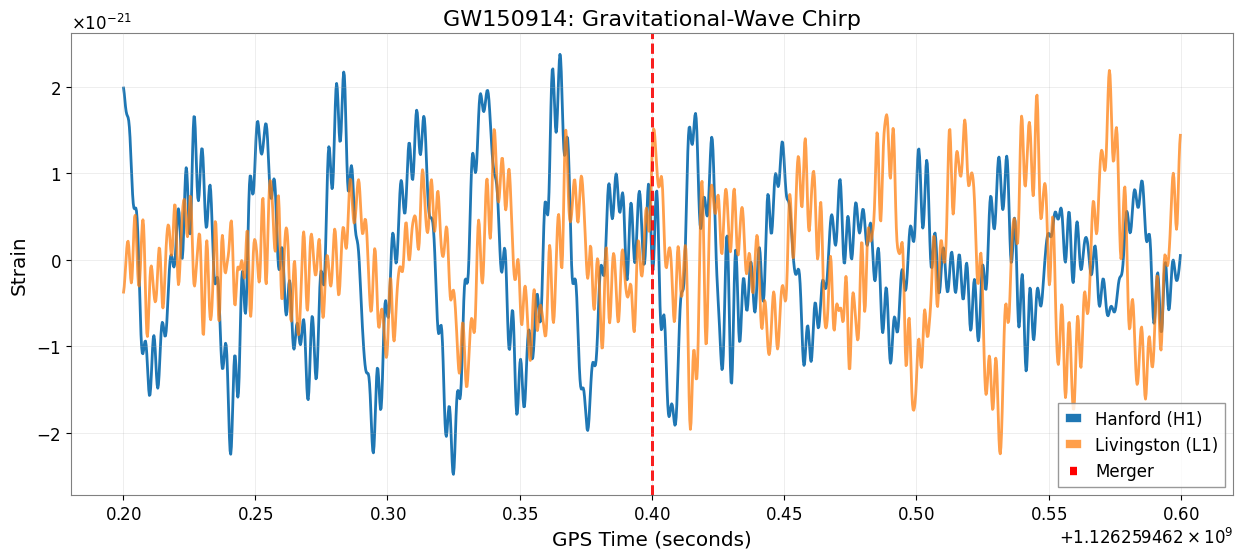

In [ ]:
plt.figure(figsize=(15,6))

plt.plot(
    h1_zoom.times.value,
    h1_zoom.value,
    label="Hanford (H1)",
    linewidth=2
)

plt.plot(
    l1_zoom.times.value,
    l1_zoom.value,
    label="Livingston (L1)",
    linewidth=2,
    alpha=0.75
)

plt.axvline(
    event_time,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Merger"
)

plt.title("GW150914: Gravitational-Wave Chirp", fontsize=16)

plt.xlabel("GPS Time (seconds)")
plt.ylabel("Strain")

plt.grid(alpha=0.3)
plt.legend()

plt.show()



## Measuring the Gravitational-Wave Signal

In [ ]:
import numpy as np

# Peak strain values
h1_peak = np.max(np.abs(h1_zoom.value))
l1_peak = np.max(np.abs(l1_zoom.value))

print(f"Maximum H1 strain : {h1_peak:.3e}")
print(f"Maximum L1 strain : {l1_peak:.3e}")

Maximum H1 strain : 2.480e-21
Maximum L1 strain : 2.243e-21


## Calculate the signal envelope

In [ ]:
from scipy.signal import hilbert, find_peaks

# Extract the observed Hanford waveform
signal = np.asarray(h1_zoom.value)
times = np.asarray(h1_zoom.times.value)

# Compute the analytic signal
analytic_signal = hilbert(signal)

# Calculate the amplitude envelope
envelope = np.abs(analytic_signal)

print("Signal envelope calculated successfully!")
print(f"Number of samples: {len(envelope)}")
print(f"Maximum envelope amplitude: {np.max(envelope):.3e}")

Signal envelope calculated successfully!
Number of samples: 1638
Maximum envelope amplitude: 2.913e-21


## Plot the observed waveform and its envelope

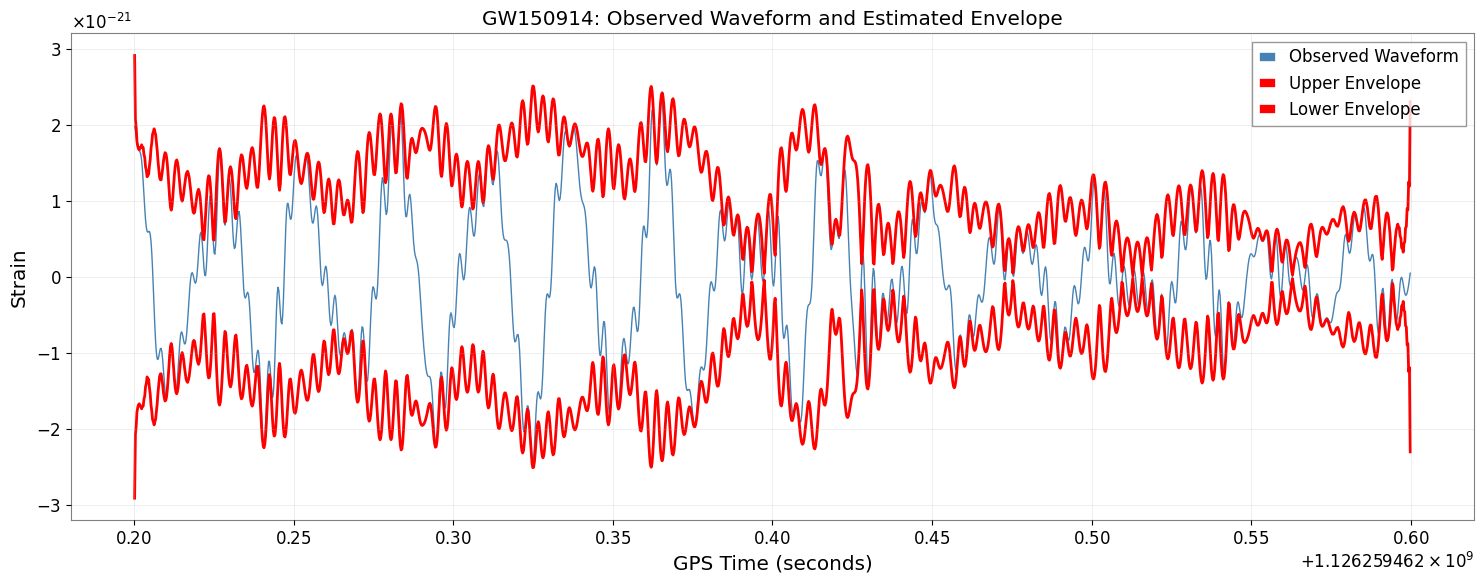

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    times,
    signal,
    color="steelblue",
    linewidth=1,
    label="Observed Waveform"
)

plt.plot(
    times,
    envelope,
    color="red",
    linewidth=2,
    label="Upper Envelope"
)

plt.plot(
    times,
    -envelope,
    color="red",
    linewidth=2,
    label="Lower Envelope"
)

plt.title("GW150914: Observed Waveform and Estimated Envelope")
plt.xlabel("GPS Time (seconds)")
plt.ylabel("Strain")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Estimate the instantaneous frequency from waveform peaks

In [ ]:
# Detect prominent positive peaks
peaks, properties = find_peaks(
    signal,
    distance=10,
    prominence=0.5 * np.std(signal)
)

peak_times = times[peaks]

# Calculate periods between consecutive peaks
periods = np.diff(peak_times)

# Convert periods into frequency estimates
frequencies = 1.0 / periods

# Assign each estimate to the midpoint between its peaks
frequency_times = (
    peak_times[:-1] + peak_times[1:]
) / 2

if len(frequencies) == 0:
    raise ValueError(
        "Too few peaks detected. Adjust the peak detection settings."
    )

print(f"Detected peaks: {len(peaks)}")
print(f"Frequency estimates: {len(frequencies)}")
print(f"Estimated frequency range: "
      f"{np.min(frequencies):.2f}–{np.max(frequencies):.2f} Hz")

Detected peaks: 51
Frequency estimates: 50
Estimated frequency range: 37.24–372.36 Hz


# Plot the estimated frequency evolution

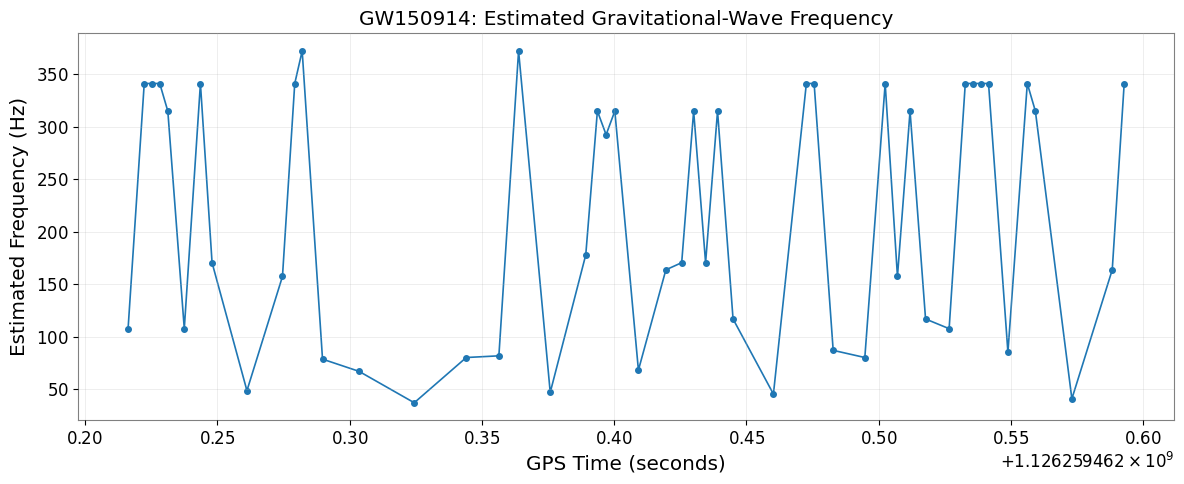

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    frequency_times,
    frequencies,
    marker="o",
    markersize=4,
    linewidth=1.2
)

plt.title("GW150914: Estimated Gravitational-Wave Frequency")
plt.xlabel("GPS Time (seconds)")
plt.ylabel("Estimated Frequency (Hz)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot the measured frequency evolution

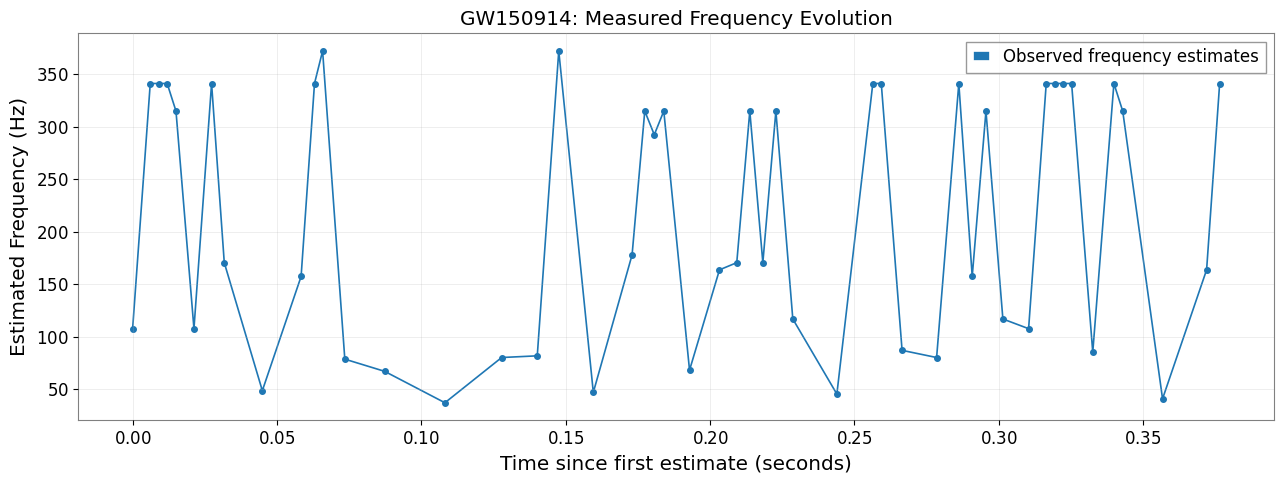

In [ ]:
# Sort measured frequency estimates chronologically
sort_idx = np.argsort(frequency_times)

frequency_times = np.asarray(frequency_times)[sort_idx]
frequencies = np.asarray(frequencies)[sort_idx]

# Plot measured estimates only
plt.figure(figsize=(13, 5))

plt.plot(
    frequency_times - frequency_times.min(),
    frequencies,
    "o-",
    markersize=4,
    linewidth=1.2,
    label="Observed frequency estimates"
)

plt.xlabel("Time since first estimate (seconds)")
plt.ylabel("Estimated Frequency (Hz)")
plt.title("GW150914: Measured Frequency Evolution")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Generate a theoretical waveform using PyCBC

In [ ]:
!pip install pycbc -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.6/168.6 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 MB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.1/203.1 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.5/53.5 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.1/48.1 MB 11.6 MB/s eta 0:00:00


In [ ]:
from pycbc.waveform import get_td_waveform

# Generate a general-relativistic binary black hole waveform
hp, hc = get_td_waveform(
    approximant="IMRPhenomD",
    mass1=36,
    mass2=29,
    delta_t=1 / 4096,
    f_lower=20
)

# Convert the plus polarization to NumPy arrays
hp_data = hp.numpy()
hp_time = hp.sample_times.numpy()

# Identify the waveform's maximum-amplitude sample
peak_idx = np.argmax(np.abs(hp_data))

# Set the theoretical merger peak to t = 0
theory_time = hp_time - hp_time[peak_idx]

print("Theoretical waveform generated successfully.")
print(f"Number of samples: {len(hp_data):,}")
print(f"Sampling rate: {1 / hp.delta_t:.0f} Hz")
print(f"Duration: {float(hp.duration):.2f} seconds")
print(f"Peak amplitude before normalization: {np.max(np.abs(hp_data)):.3e}")

/usr/lib/python3.13/importlib/__init__.py:88: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  return _bootstrap._gcd_import(name[level:], package, level)


Theoretical waveform generated successfully.
Number of samples: 65,536
Sampling rate: 4096 Hz
Duration: 16.00 seconds
Peak amplitude before normalization: 7.539e-19


## Plot the complete theoretical waveform

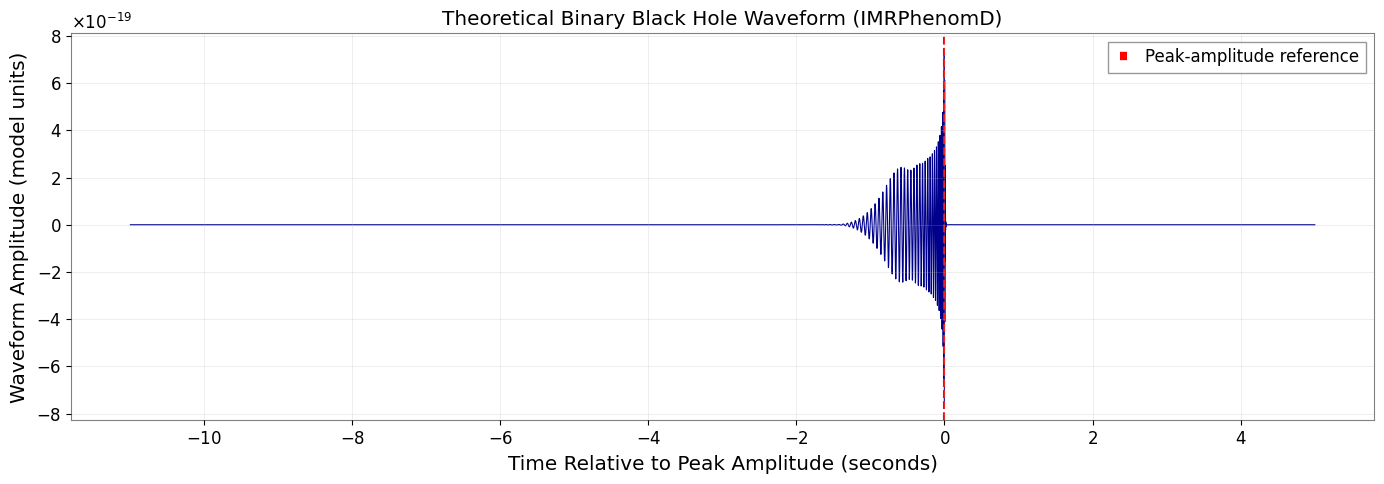

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    theory_time,
    hp_data,
    linewidth=0.8,
    color="darkblue"
)

plt.axvline(0, color="red", linestyle="--", label="Peak-amplitude reference")

plt.title("Theoretical Binary Black Hole Waveform (IMRPhenomD)")
plt.xlabel("Time Relative to Peak Amplitude (seconds)")
plt.ylabel("Waveform Amplitude (model units)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Normalize the theoretical waveform and inspect its final second

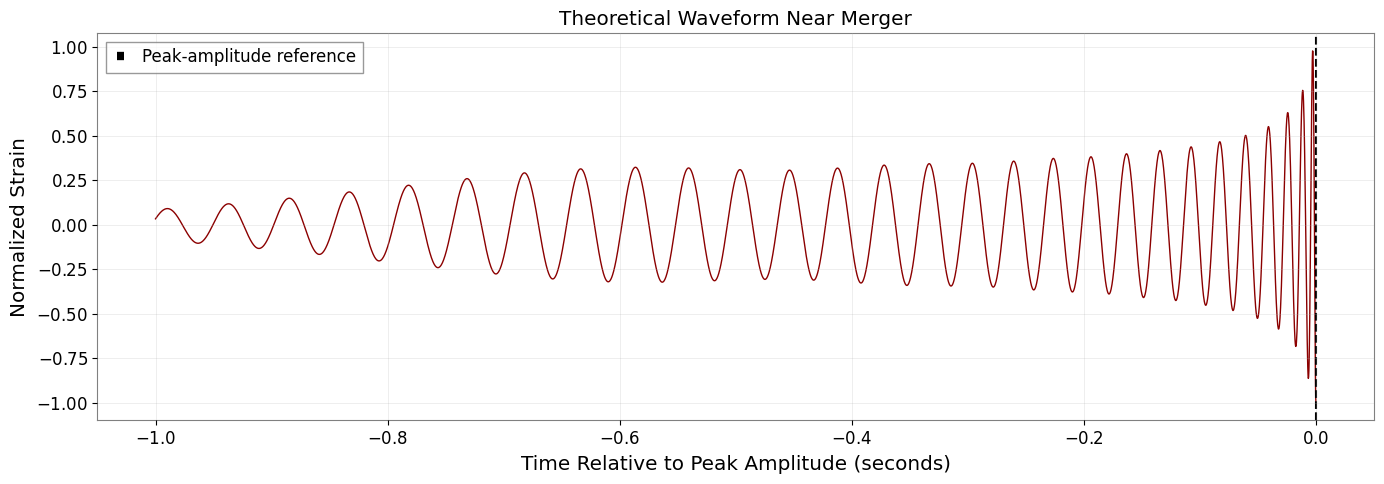

In [ ]:
# Normalize by the maximum absolute amplitude
hp_norm = hp_data / np.max(np.abs(hp_data))

# Select the final second relative to the peak-amplitude reference
final_second = (theory_time >= -1.0) & (theory_time <= 0.0)

plt.figure(figsize=(14, 5))

plt.plot(
    theory_time[final_second],
    hp_norm[final_second],
    color="darkred",
    linewidth=1
)

plt.axvline(0, color="black", linestyle="--", label="Peak-amplitude reference")

plt.title("Theoretical Waveform Near Merger")
plt.xlabel("Time Relative to Peak Amplitude (seconds)")
plt.ylabel("Normalized Strain")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Prepare both waveforms for a fairer visual comparison

In [ ]:
from scipy.signal import butter, sosfiltfilt

sample_rate = 4096

# Filter the theoretical waveform using the observed frequency band
sos = butter(
    4,
    [30, 400],
    btype="bandpass",
    fs=sample_rate,
    output="sos"
)

hp_filtered = sosfiltfilt(sos, hp_data)

# Normalize the theoretical waveform
hp_filtered_norm = hp_filtered / np.max(np.abs(hp_filtered))

# Prepare the observed Hanford waveform
obs = np.asarray(h1_zoom.value, dtype=float)
obs_norm = obs / np.max(np.abs(obs))
obs_times = np.asarray(h1_zoom.times.value)

# Locate the maximum absolute amplitude in each waveform
obs_peak_idx = np.argmax(np.abs(obs_norm))
theory_peak_idx = np.argmax(np.abs(hp_filtered_norm))

# Align both peak-amplitude samples to t = 0
obs_time_aligned = obs_times - obs_times[obs_peak_idx]
theory_time_aligned = (
    hp.sample_times.numpy()
    - hp.sample_times.numpy()[theory_peak_idx]
)

print("Both waveform peaks aligned to t = 0.")
print(f"Observed peak GPS time: {obs_times[obs_peak_idx]:.6f}")
print(f"Observed samples: {len(obs_norm):,}")
print(f"Theoretical samples: {len(hp_filtered_norm):,}")

Both waveform peaks aligned to t = 0.
Observed peak GPS time: 1126259462.324951
Observed samples: 1,638
Theoretical samples: 65,536


## Compare observed and theoretical waveform shapes

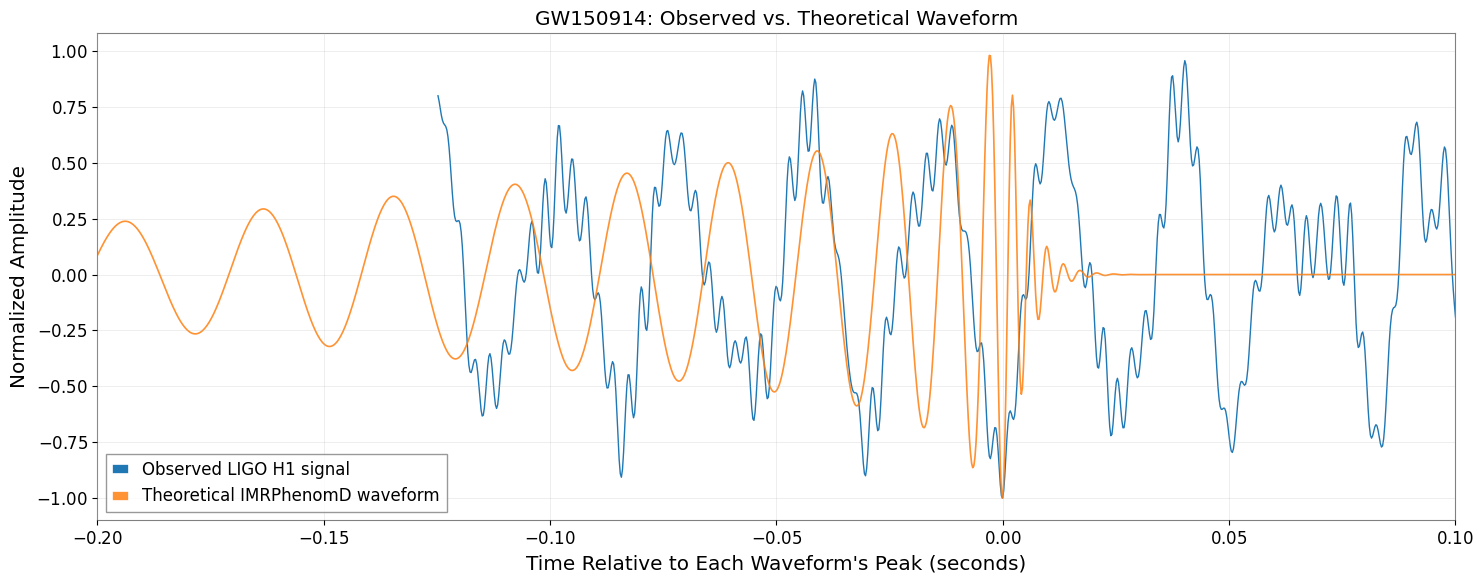

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    obs_time_aligned,
    obs_norm,
    label="Observed LIGO H1 signal",
    linewidth=1
)

plt.plot(
    theory_time_aligned,
    hp_filtered_norm,
    label="Theoretical IMRPhenomD waveform",
    linewidth=1.2,
    alpha=0.85
)

plt.xlim(-0.2, 0.1)

plt.xlabel("Time Relative to Each Waveform's Peak (seconds)")
plt.ylabel("Normalized Amplitude")
plt.title("GW150914: Observed vs. Theoretical Waveform")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Characterize detector noise

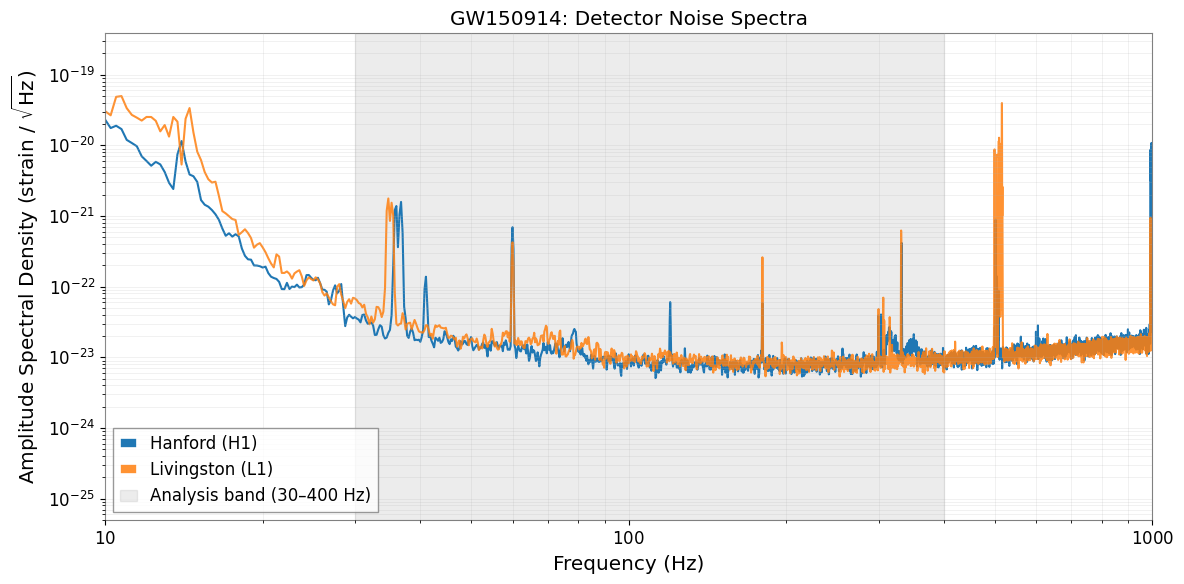

PSD and ASD estimation completed.
Sampling rate: 4096 Hz
H1 PSD array length: 8,193
L1 PSD array length: 8,193


In [ ]:
from scipy.signal import welch

# Sampling rate — explicitly convert Hz to a plain number
fs = h1.sample_rate.to_value("Hz")

# Convert strain data to NumPy arrays
h1_data = np.asarray(h1.value, dtype=float)
l1_data = np.asarray(l1.value, dtype=float)

# Estimate power spectral density (PSD)
nperseg = int(fs * 4)  # 4-second segments

frequencies_h1, psd_h1 = welch(
    h1_data,
    fs=fs,
    window="hann",
    nperseg=nperseg,
    detrend="constant",
    scaling="density"
)

frequencies_l1, psd_l1 = welch(
    l1_data,
    fs=fs,
    window="hann",
    nperseg=nperseg,
    detrend="constant",
    scaling="density"
)

# Convert PSD to amplitude spectral density (ASD)
asd_h1 = np.sqrt(psd_h1)
asd_l1 = np.sqrt(psd_l1)

# Plot detector noise spectra
plt.figure(figsize=(12, 6))

plt.loglog(
    frequencies_h1[1:],
    asd_h1[1:],
    label="Hanford (H1)"
)

plt.loglog(
    frequencies_l1[1:],
    asd_l1[1:],
    label="Livingston (L1)",
    alpha=0.85
)

plt.axvspan(
    30, 400,
    color="gray",
    alpha=0.15,
    label="Analysis band (30–400 Hz)"
)

plt.xlim(10, 1000)
plt.xlabel("Frequency (Hz)")
plt.ylabel(r"Amplitude Spectral Density (strain / $\sqrt{\mathrm{Hz}}$)")
plt.title("GW150914: Detector Noise Spectra")
plt.grid(True, which="both", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

print("PSD and ASD estimation completed.")
print(f"Sampling rate: {fs:.0f} Hz")
print(f"H1 PSD array length: {len(psd_h1):,}")
print(f"L1 PSD array length: {len(psd_l1):,}")

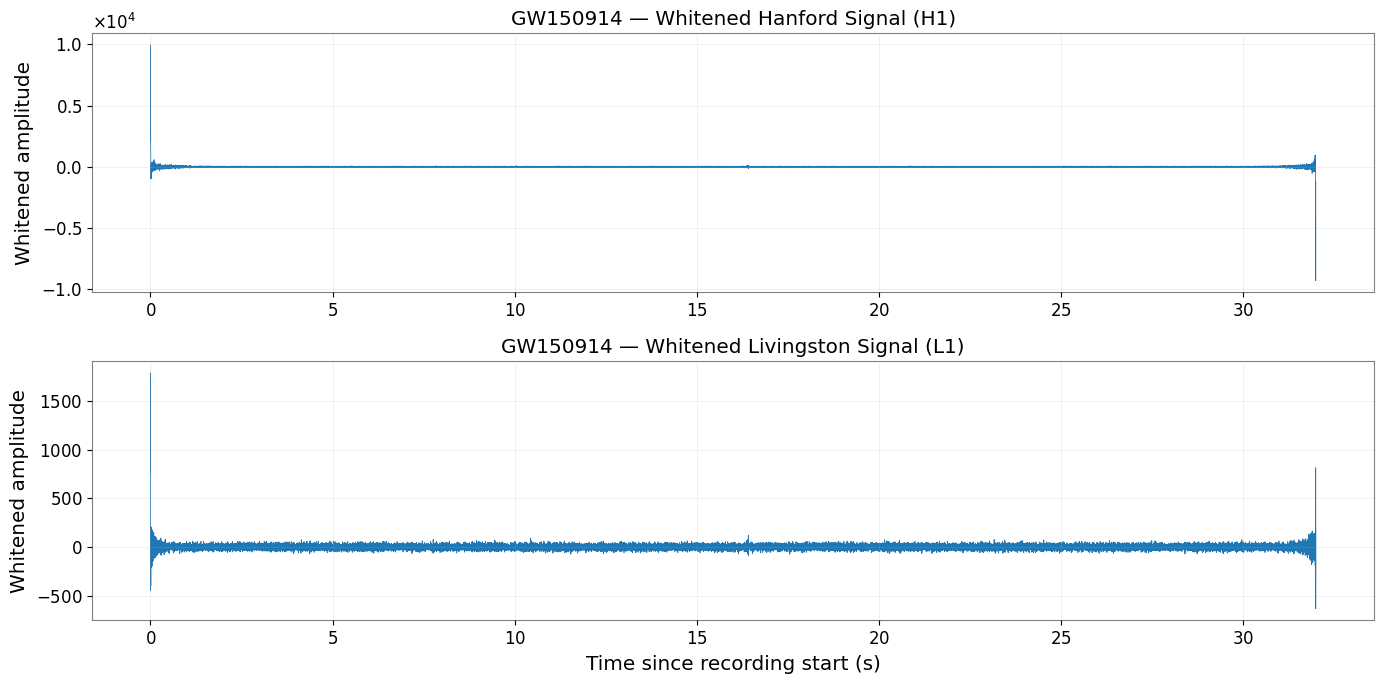

Whitening completed for H1 and L1.
Sampling rate: 4096 Hz
H1 whitened samples: 131,072
L1 whitened samples: 131,072


In [ ]:
# Explicitly convert GWpy's unit-aware sampling rate
fs = float(h1.sample_rate.to_value("Hz"))

h1_data = np.asarray(h1.value, dtype=float)
l1_data = np.asarray(l1.value, dtype=float)

nperseg = int(fs * 4)

freq_h1, psd_h1 = welch(
    h1_data, fs=fs, window="hann",
    nperseg=nperseg, detrend="constant",
    scaling="density"
)

freq_l1, psd_l1 = welch(
    l1_data, fs=fs, window="hann",
    nperseg=nperseg, detrend="constant",
    scaling="density"
)

def whiten_signal(data, psd_freq, psd, fs):
    n = len(data)
    fft_freq = np.fft.rfftfreq(n, d=1 / fs)
    data_fft = np.fft.rfft(data - np.mean(data))

    psd_interp = np.interp(fft_freq, psd_freq, psd)

    valid = (
        (psd_interp > 0)
        & (fft_freq >= 30)
        & (fft_freq <= 400)
    )

    whitened_fft = np.zeros_like(data_fft, dtype=complex)
    whitened_fft[valid] = (
        data_fft[valid] / np.sqrt(psd_interp[valid])
    )

    return np.fft.irfft(whitened_fft, n=n)

h1_white = whiten_signal(h1_data, freq_h1, psd_h1, fs)
l1_white = whiten_signal(l1_data, freq_l1, psd_l1, fs)

time_h1 = np.arange(len(h1_white)) / fs
time_l1 = np.arange(len(l1_white)) / fs

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

axes[0].plot(time_h1, h1_white, linewidth=0.6)
axes[0].set_title("GW150914 — Whitened Hanford Signal (H1)")
axes[0].set_ylabel("Whitened amplitude")
axes[0].grid(alpha=0.25)

axes[1].plot(time_l1, l1_white, linewidth=0.6)
axes[1].set_title("GW150914 — Whitened Livingston Signal (L1)")
axes[1].set_xlabel("Time since recording start (s)")
axes[1].set_ylabel("Whitened amplitude")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("Whitening completed for H1 and L1.")
print(f"Sampling rate: {fs:.0f} Hz")
print(f"H1 whitened samples: {len(h1_white):,}")
print(f"L1 whitened samples: {len(l1_white):,}")

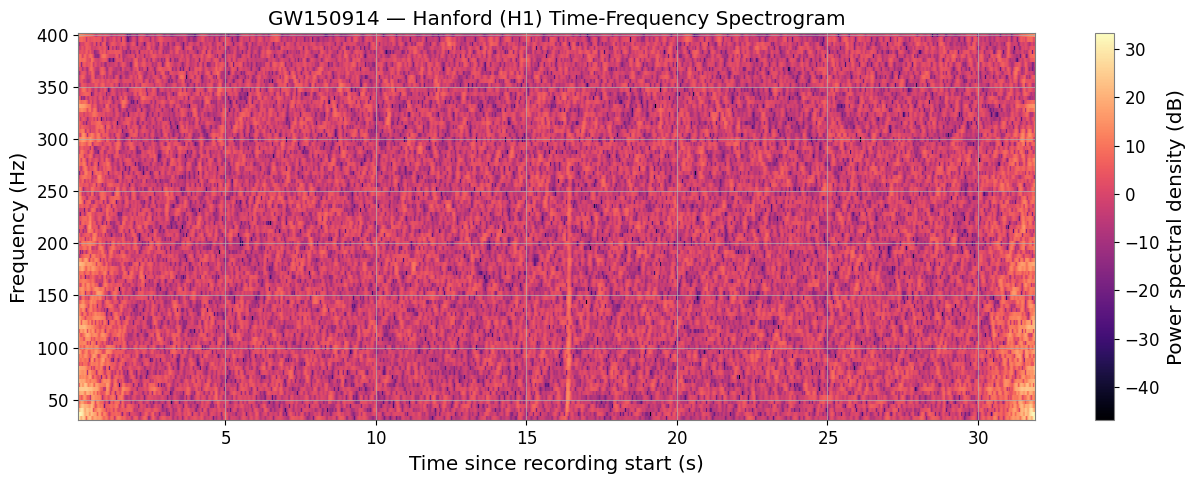

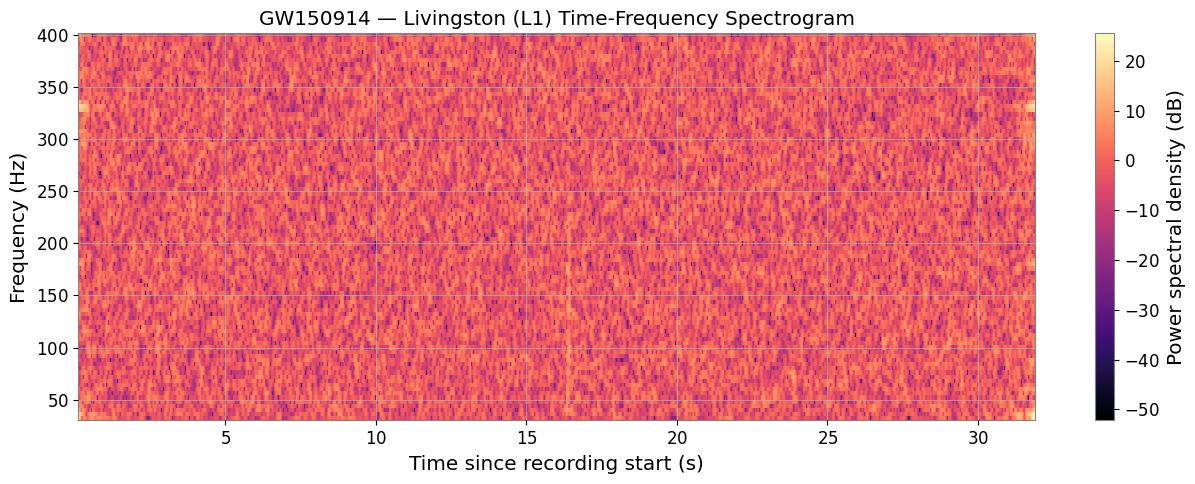

Time-frequency spectrograms generated for both detectors.


In [ ]:
from scipy.signal import spectrogram

fs = float(h1.sample_rate.to_value("Hz"))

def plot_spectrogram(data, detector_name):
    frequencies, times, power = spectrogram(
        data,
        fs=fs,
        window="hann",
        nperseg=1024,
        noverlap=896,
        detrend="constant",
        scaling="density",
        mode="psd"
    )

    # Display only the main analysis band
    mask = (frequencies >= 30) & (frequencies <= 400)

    plt.figure(figsize=(13, 5))
    plt.pcolormesh(
        times,
        frequencies[mask],
        10 * np.log10(power[mask, :] + 1e-60),
        shading="auto",
        cmap="magma"
    )
    plt.xlabel("Time since recording start (s)")
    plt.ylabel("Frequency (Hz)")
    plt.title(f"GW150914 — {detector_name} Time-Frequency Spectrogram")
    plt.colorbar(label="Power spectral density (dB)")
    plt.tight_layout()
    plt.show()

plot_spectrogram(h1_white, "Hanford (H1)")
plot_spectrogram(l1_white, "Livingston (L1)")

print("Time-frequency spectrograms generated for both detectors.")

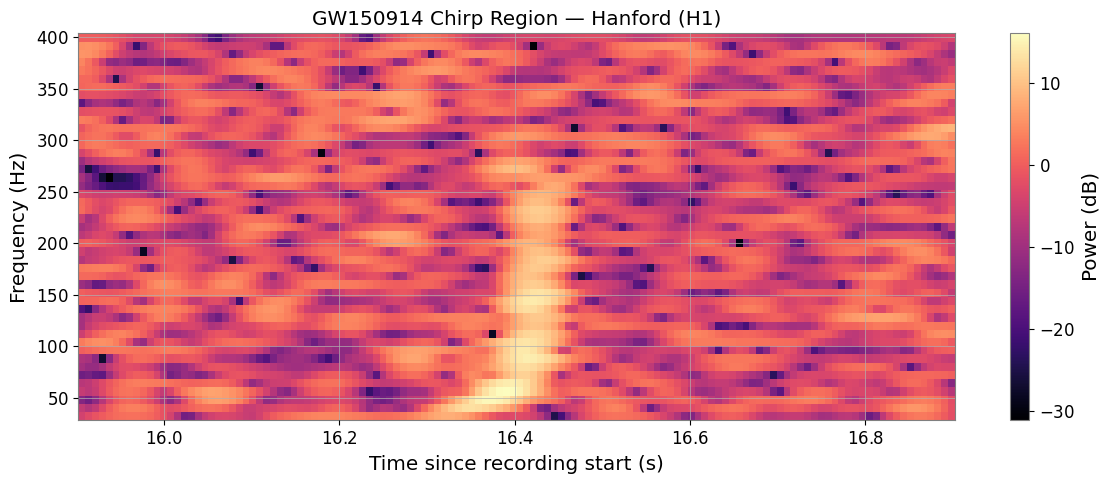

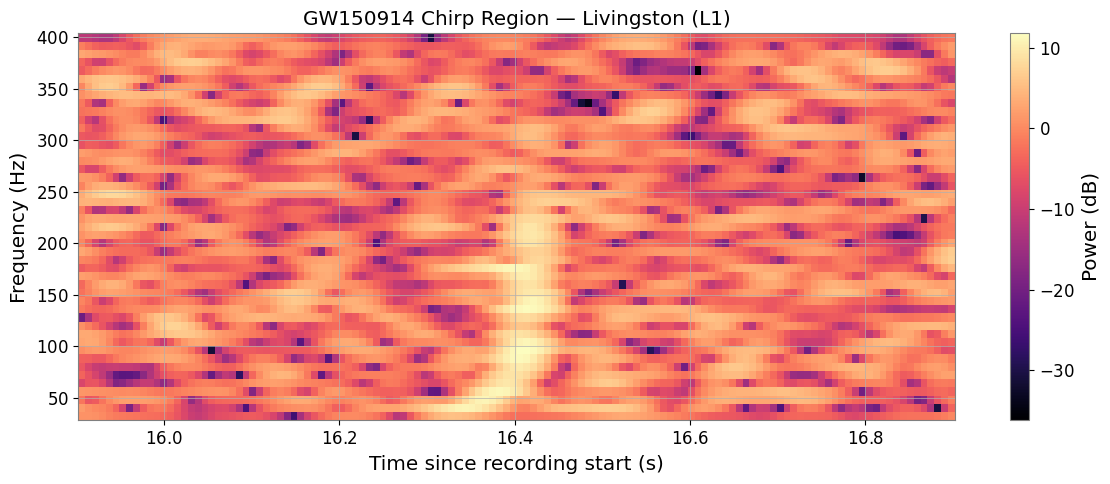

In [ ]:
# Zoom around the GW150914 event
event_relative_time = 16.4
window = 0.5  # seconds on each side

for data, detector in [
    (h1_white, "Hanford (H1)"),
    (l1_white, "Livingston (L1)")
]:
    frequencies, times, power = spectrogram(
        data,
        fs=fs,
        window="hann",
        nperseg=512,
        noverlap=480,
        scaling="density",
        mode="psd"
    )

    time_mask = (
        (times >= event_relative_time - window) &
        (times <= event_relative_time + window)
    )
    freq_mask = (frequencies >= 30) & (frequencies <= 400)

    plt.figure(figsize=(12, 5))
    plt.pcolormesh(
        times[time_mask],
        frequencies[freq_mask],
        10 * np.log10(power[np.ix_(freq_mask, time_mask)] + 1e-60),
        shading="auto",
        cmap="magma"
    )
    plt.xlabel("Time since recording start (s)")
    plt.ylabel("Frequency (Hz)")
    plt.title(f"GW150914 Chirp Region — {detector}")
    plt.colorbar(label="Power (dB)")
    plt.tight_layout()
    plt.show()

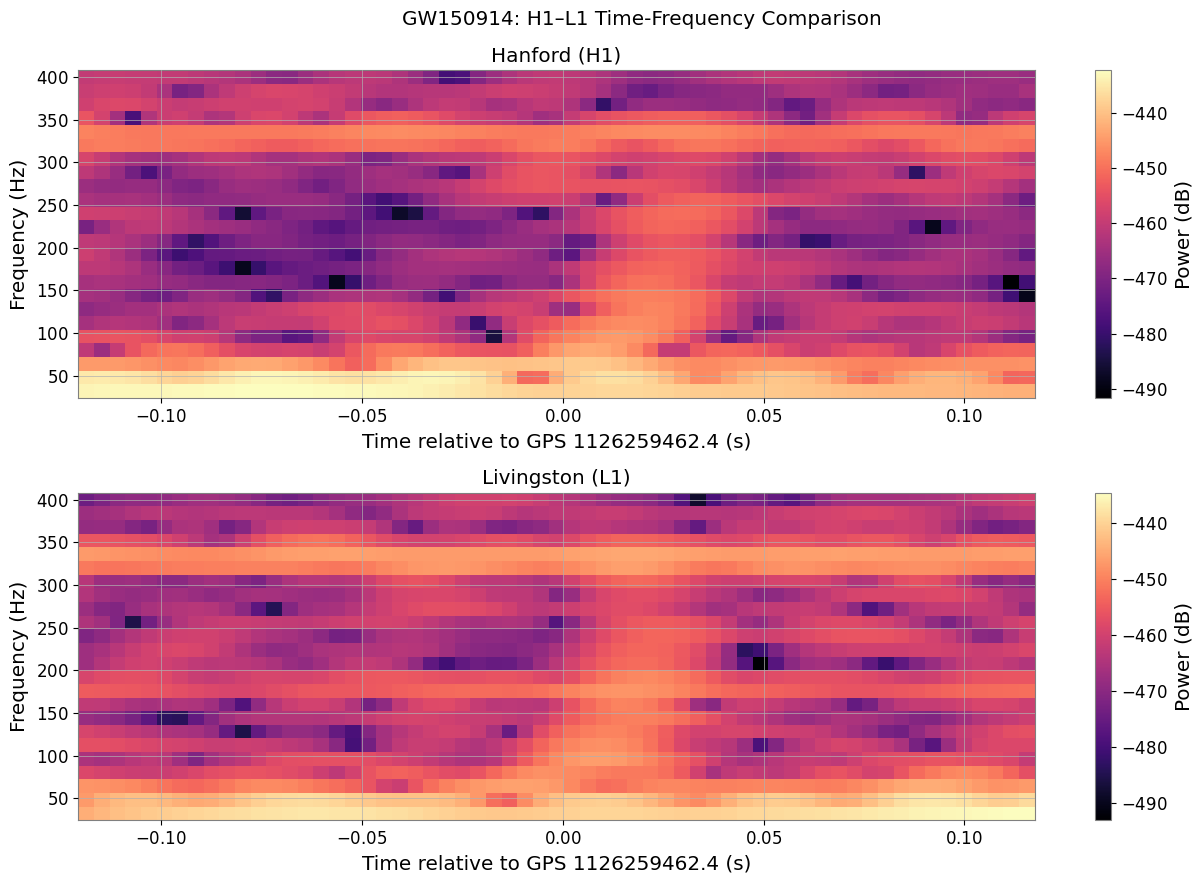

In [ ]:
fs = float(h1.sample_rate.to_value("Hz"))
event_time = 1126259462.4

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

for ax, series, detector in [
    (axes[0], h1_filtered, "Hanford (H1)"),
    (axes[1], l1_filtered, "Livingston (L1)")
]:
    relative_time = np.asarray(series.times.value) - event_time
    data = np.asarray(series.value, dtype=float)

    mask = (relative_time >= -0.15) & (relative_time <= 0.15)
    event_data = data[mask]

    frequencies, times, power = spectrogram(
        event_data,
        fs=fs,
        window="hann",
        nperseg=256,
        noverlap=240,
        detrend="constant",
        scaling="density",
        mode="psd"
    )

    freq_mask = (frequencies >= 30) & (frequencies <= 400)

    mesh = ax.pcolormesh(
        times - 0.15,
        frequencies[freq_mask],
        10 * np.log10(power[freq_mask] + 1e-60),
        shading="auto",
        cmap="magma"
    )

    ax.set_title(detector)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_xlabel("Time relative to GPS 1126259462.4 (s)")
    fig.colorbar(mesh, ax=ax, label="Power (dB)")

plt.suptitle("GW150914: H1–L1 Time-Frequency Comparison")
plt.tight_layout()
plt.show()

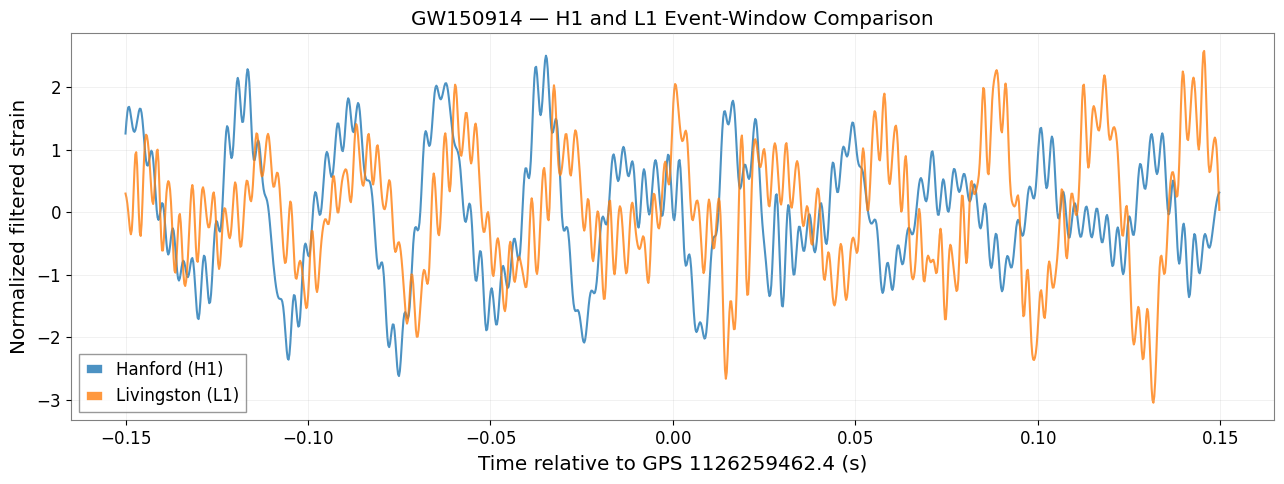

In [ ]:
fs = float(h1.sample_rate.to_value("Hz"))
event_time = 1126259462.4

# Extract a short event window from both detectors
def extract_event(series, event_time, half_width=0.15):
    times = np.asarray(series.times.value)
    data = np.asarray(series.value, dtype=float)
    mask = (
        (times >= event_time - half_width) &
        (times <= event_time + half_width)
    )
    return times[mask] - event_time, data[mask]

t_h1, x_h1 = extract_event(h1_filtered, event_time)
t_l1, x_l1 = extract_event(l1_filtered, event_time)

# Normalize for shape comparison
x_h1 = x_h1 / (np.std(x_h1) + 1e-30)
x_l1 = x_l1 / (np.std(x_l1) + 1e-30)

plt.figure(figsize=(13, 5))
plt.plot(t_h1, x_h1, label="Hanford (H1)", alpha=0.8)
plt.plot(t_l1, x_l1, label="Livingston (L1)", alpha=0.8)
plt.xlabel("Time relative to GPS 1126259462.4 (s)")
plt.ylabel("Normalized filtered strain")
plt.title("GW150914 — H1 and L1 Event-Window Comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Final addition: matched-filter analysis

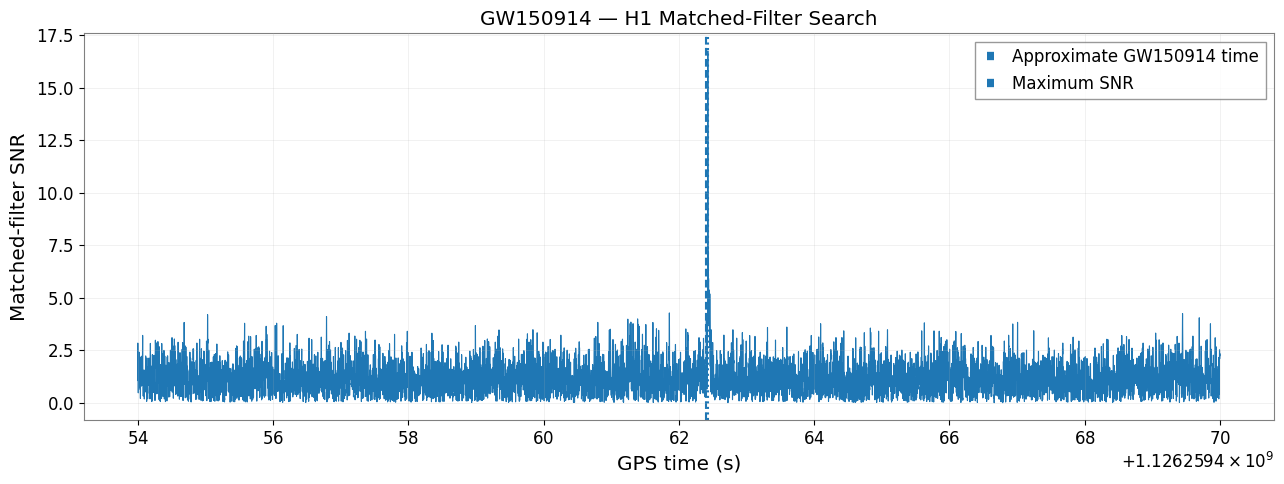

Maximum single-detector SNR: 16.76
Time of maximum SNR: 1126259462.429443 GPS


In [ ]:
# Convert the existing H1 strain into a PyCBC time series
fs = int(h1.sample_rate.to_value("Hz"))
strain = np.asarray(h1.value, dtype=np.float64)

data = TimeSeries(
    strain,
    delta_t=1.0 / fs,
    epoch=float(h1.t0.value)
)

# Estimate the detector noise PSD
psd = data.psd(4)
psd = interpolate(psd, data.delta_f)
psd = inverse_spectrum_truncation(
    psd,
    int(4 * fs),
    low_frequency_cutoff=20
)

# Generate a theoretical binary-black-hole waveform
hp, hc = get_fd_waveform(
    approximant="IMRPhenomD",
    mass1=36,
    mass2=29,
    delta_f=data.delta_f,
    f_lower=20
)

# Match the template's frequency-domain length to the data
hp.resize(len(data) // 2 + 1)

# Calculate matched-filter SNR
snr = matched_filter(
    hp,
    data,
    psd=psd,
    low_frequency_cutoff=20,
    high_frequency_cutoff=400
)

# Exclude edge regions affected by filter wraparound
snr = snr[len(snr) // 4: 3 * len(snr) // 4]

snr_times = snr.sample_times.numpy()
snr_values = np.abs(snr.numpy())
peak_idx = np.argmax(snr_values)

plt.figure(figsize=(13, 5))
plt.plot(snr_times, snr_values, linewidth=0.8)
plt.axvline(
    1126259462.4,
    linestyle="--",
    label="Approximate GW150914 time"
)
plt.axvline(
    snr_times[peak_idx],
    linestyle=":",
    label="Maximum SNR"
)
plt.xlabel("GPS time (s)")
plt.ylabel("Matched-filter SNR")
plt.title("GW150914 — H1 Matched-Filter Search")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Maximum single-detector SNR: {snr_values[peak_idx]:.2f}")
print(f"Time of maximum SNR: {snr_times[peak_idx]:.6f} GPS")

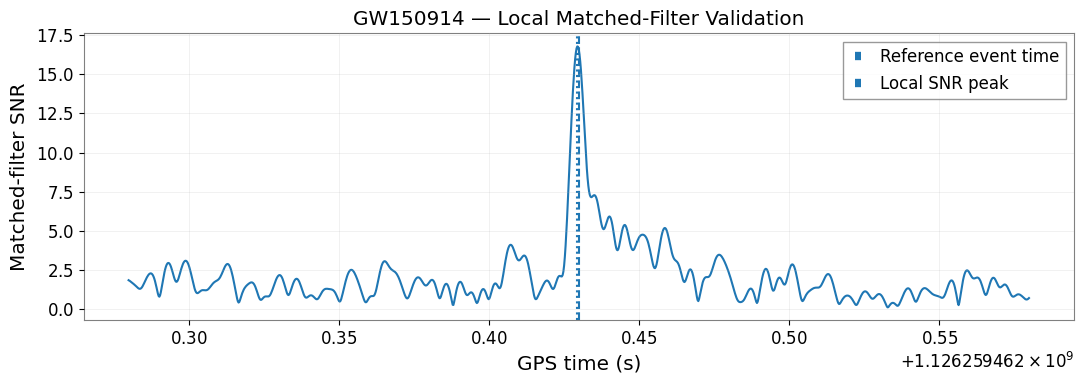

Local peak SNR: 16.76
Local peak GPS time: 1126259462.429443
Offset from reference: -0.56 ms


In [ ]:
snr_times = np.asarray(snr.sample_times.numpy())
snr_values = np.abs(np.asarray(snr.numpy()))

event_time = 1126259462.43
window = 0.15

mask = np.abs(snr_times - event_time) <= window

if not np.any(mask):
    print("No SNR samples found in the event window.")
else:
    local_times = snr_times[mask]
    local_snr = snr_values[mask]

    peak_idx = np.argmax(local_snr)
    peak_time = local_times[peak_idx]
    peak_value = local_snr[peak_idx]

    plt.figure(figsize=(11, 4))
    plt.plot(local_times, local_snr)
    plt.axvline(
        event_time, linestyle="--",
        label="Reference event time"
    )
    plt.axvline(
        peak_time, linestyle=":",
        label="Local SNR peak"
    )
    plt.xlabel("GPS time (s)")
    plt.ylabel("Matched-filter SNR")
    plt.title("GW150914 — Local Matched-Filter Validation")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"Local peak SNR: {peak_value:.2f}")
    print(f"Local peak GPS time: {peak_time:.6f}")
    print(f"Offset from reference: {(peak_time-event_time)*1000:.2f} ms")

## Prepare the existing H1 and L1 data

In [ ]:

# AI Gravitational-Wave Detection
# Step 1: Prepare the existing GW150914 data

# Reuse the filtered data created earlier in this notebook
h1_data = np.asarray(h1_filtered.value, dtype=np.float32)
l1_data = np.asarray(l1_filtered.value, dtype=np.float32)

h1_times = np.asarray(h1_filtered.times.value)
l1_times = np.asarray(l1_filtered.times.value)

fs = int(h1_filtered.sample_rate.to_value("Hz"))

# Check that both detectors can be combined sample by sample
assert fs == 4096, f"Unexpected sampling rate: {fs}"
assert len(h1_data) == len(l1_data), "Detector lengths differ"
assert np.allclose(h1_times, l1_times, atol=1e-6), (
    "H1 and L1 timestamps are not aligned"
)

# Divide the 32-second recording into non-overlapping 1-second windows
window_seconds = 1
window_samples = fs * window_seconds

usable_samples = (len(h1_data) // window_samples) * window_samples

h1_data = h1_data[:usable_samples]
l1_data = l1_data[:usable_samples]

# Shape: (number of windows, samples per window, detector channels)
X_gw150914_unlabelled = np.stack(
    [
        h1_data.reshape(-1, window_samples),
        l1_data.reshape(-1, window_samples)
    ],
    axis=-1
)

print("Data preparation complete.")
print("Sampling rate:", fs, "Hz")
print("Window duration:", window_seconds, "second")
print("Samples per detector per window:", window_samples)
print("Number of windows:", len(X_gw150914_unlabelled))
print("Model input shape:", X_gw150914_unlabelled.shape)
print("Detector channels: H1 and L1")
print("Labels assigned: No — these windows are not yet labelled.")


Data preparation complete.
Sampling rate: 4096 Hz
Window duration: 1 second
Samples per detector per window: 4096
Number of windows: 32
Model input shape: (32, 4096, 2)
Detector channels: H1 and L1
Labels assigned: No — these windows are not yet labelled.


## Visualise the model input

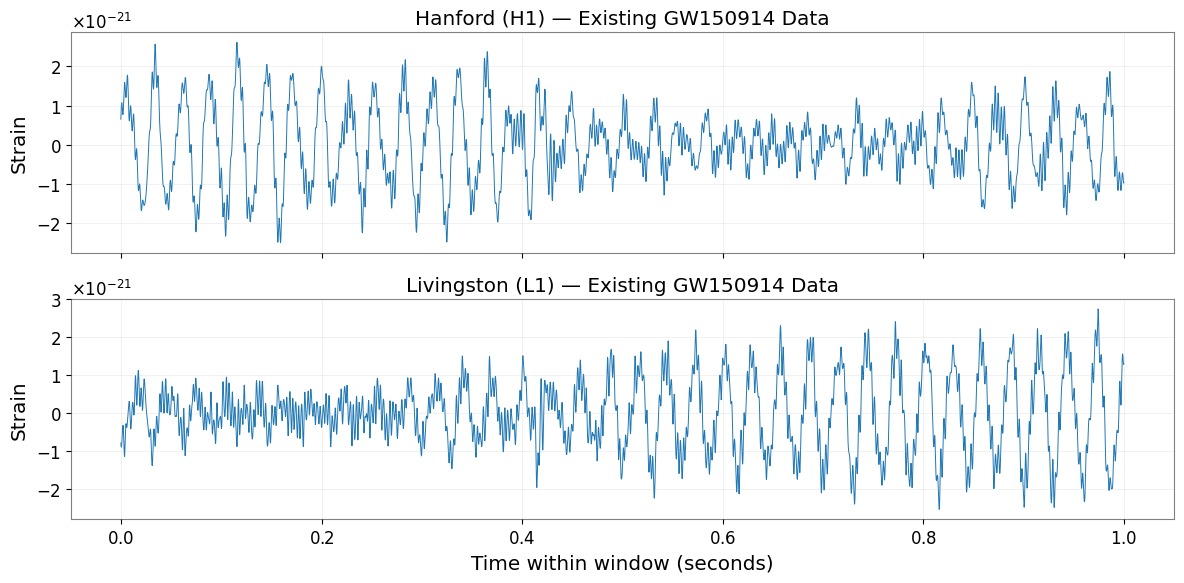

In [ ]:

# Plot one existing window from both detectors

window_index = 16  # Approximate window containing GW150914

window = X_gw150914_unlabelled[window_index]
time_axis = np.arange(window_samples) / fs

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(time_axis, window[:, 0], linewidth=0.7)
axes[0].set_title("Hanford (H1) — Existing GW150914 Data")
axes[0].set_ylabel("Strain")
axes[0].grid(alpha=0.25)

axes[1].plot(time_axis, window[:, 1], linewidth=0.7)
axes[1].set_title("Livingston (L1) — Existing GW150914 Data")
axes[1].set_xlabel("Time within window (seconds)")
axes[1].set_ylabel("Strain")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


## Check TensorFlow and prepare for labelled training

In [ ]:

%pip -q install tensorflow

import tensorflow as tf
from scipy.signal import butter, sosfiltfilt

print("TensorFlow version:", tf.__version__)
print("Existing data shape:", X_gw150914_unlabelled.shape)
print("All input values finite:", np.isfinite(X_gw150914_unlabelled).all())


TensorFlow version: 2.21.0
Existing data shape: (32, 4096, 2)
All input values finite: True


## Download additional real detector noise

In [ ]:

# Step 4: Fetch additional off-event detector data

gps_event = 1126259462

# A separate 128-second stretch, ending well before GW150914
noise_start = gps_event - 300
noise_end = gps_event - 172

try:
    h1_noise = GWpyTimeSeries.fetch_open_data(
        "H1", noise_start, noise_end, cache=False
    )
    l1_noise = GWpyTimeSeries.fetch_open_data(
        "L1", noise_start, noise_end, cache=False
    )

    h1_noise_data = np.asarray(h1_noise.value, dtype=np.float32)
    l1_noise_data = np.asarray(l1_noise.value, dtype=np.float32)

    noise_fs_h1 = float(h1_noise.sample_rate.to_value("Hz"))
    noise_fs_l1 = float(l1_noise.sample_rate.to_value("Hz"))

    print("Additional detector data downloaded.")
    print("H1 samples:", len(h1_noise_data))
    print("L1 samples:", len(l1_noise_data))
    print("H1 sampling rate:", noise_fs_h1, "Hz")
    print("L1 sampling rate:", noise_fs_l1, "Hz")
    print("H1 values finite:", np.isfinite(h1_noise_data).all())
    print("L1 values finite:", np.isfinite(l1_noise_data).all())

    assert noise_fs_h1 == 4096 and noise_fs_l1 == 4096
    assert np.isfinite(h1_noise_data).all()
    assert np.isfinite(l1_noise_data).all()

except Exception as exc:
    print("Data download or validation failed:")
    print(type(exc).__name__, str(exc))


Additional detector data downloaded.
H1 samples: 524288
L1 samples: 524288
H1 sampling rate: 4096.0 Hz
L1 sampling rate: 4096.0 Hz
H1 values finite: True
L1 values finite: True


In [ ]:

# Step 5: Query data-quality flags for both detectors

from pycbc import dq

try:
    h1_segments = dq.query_flag(
        "H1", "DATA", noise_start, noise_end
    )
    l1_segments = dq.query_flag(
        "L1", "DATA", noise_start, noise_end
    )

    def show_segments(name, segments):
        print(f"\n{name} valid DATA intervals:")
        total_seconds = 0

        for segment in segments:
            start, end = float(segment[0]), float(segment[1])
            duration = end - start
            total_seconds += duration
            print(
                f"  GPS {start:.0f} to {end:.0f}"
                f" ({duration:.1f} seconds)"
            )

        print(f"Total flagged-valid duration: {total_seconds:.1f} s")

    show_segments("Hanford (H1)", h1_segments)
    show_segments("Livingston (L1)", l1_segments)

    # Intervals valid at BOTH detectors
    common_segments = h1_segments & l1_segments

    show_segments("Common H1 + L1", common_segments)

except Exception as exc:
    print("Could not retrieve data-quality flags.")
    print(type(exc).__name__, str(exc))
    print(
        "Do not assume the data is quality-verified. "
        "We will troubleshoot this before assigning labels."
    )



Hanford (H1) valid DATA intervals:
  GPS 1126259162 to 1126259290 (128.0 seconds)
Total flagged-valid duration: 128.0 s

Livingston (L1) valid DATA intervals:
  GPS 1126259162 to 1126259290 (128.0 seconds)
Total flagged-valid duration: 128.0 s

Common H1 + L1 valid DATA intervals:
  GPS 1126259162 to 1126259290 (128.0 seconds)
Total flagged-valid duration: 128.0 s


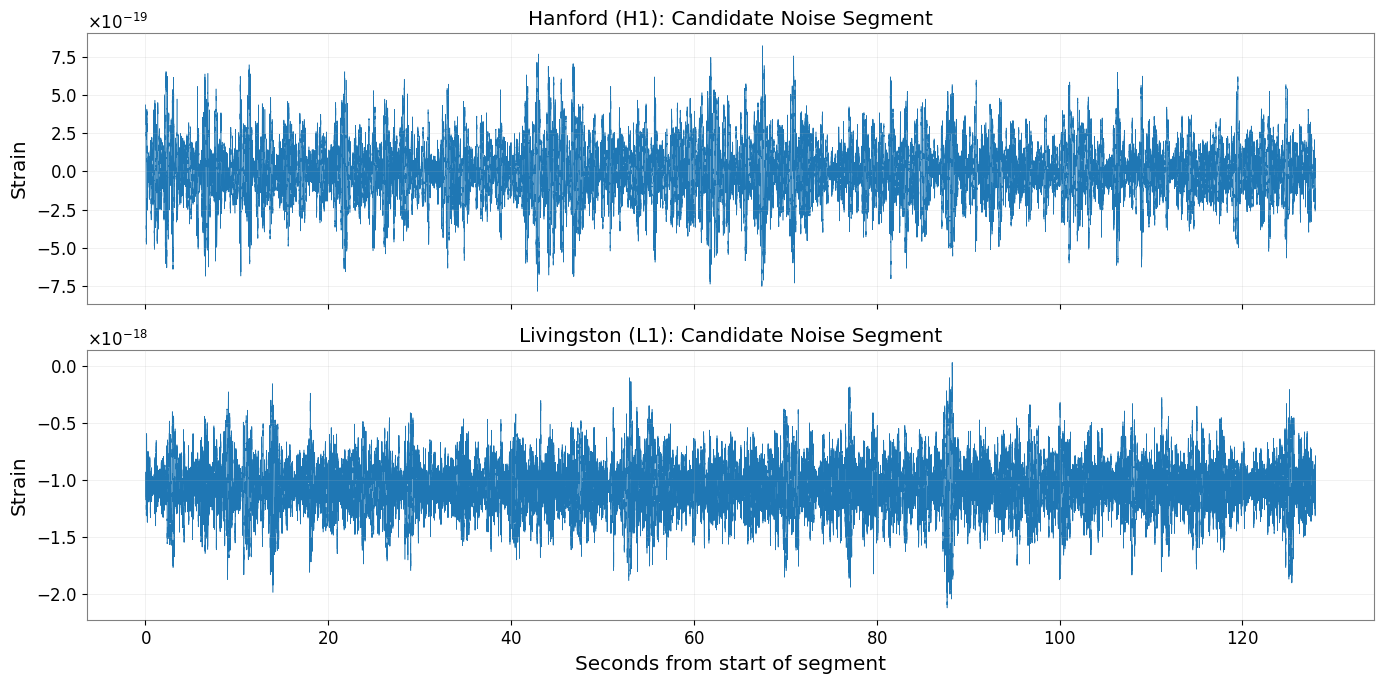

H1 strain standard deviation: 2.0188152e-19
L1 strain standard deviation: 2.3254702e-19
H1 finite values: True
L1 finite values: True


In [ ]:
# Plot the raw strain from the additional 128-second segment
time_axis = np.arange(len(h1_noise_data)) / noise_fs_h1

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(time_axis, h1_noise_data, linewidth=0.4)
axes[0].set_title("Hanford (H1): Candidate Noise Segment")
axes[0].set_ylabel("Strain")
axes[0].grid(alpha=0.25)

axes[1].plot(time_axis, l1_noise_data, linewidth=0.4)
axes[1].set_title("Livingston (L1): Candidate Noise Segment")
axes[1].set_ylabel("Strain")
axes[1].set_xlabel("Seconds from start of segment")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("H1 strain standard deviation:", np.std(h1_noise_data))
print("L1 strain standard deviation:", np.std(l1_noise_data))
print("H1 finite values:", np.isfinite(h1_noise_data).all())
print("L1 finite values:", np.isfinite(l1_noise_data).all())


In [ ]:


def inspect_extremes(data, detector, fs):
    abs_data = np.abs(data)
    indices = np.argsort(abs_data)[-10:][::-1]

    print(f"\n{detector}: 10 largest absolute strain samples")
    print("Rank | Time (s) | Strain")

    for rank, idx in enumerate(indices, start=1):
        print(
            f"{rank:>4} | {idx / fs:>8.3f} | "
            f"{data[idx]:.4e}"
        )

inspect_extremes(h1_noise_data, "H1", noise_fs_h1)
inspect_extremes(l1_noise_data, "L1", noise_fs_l1)



H1: 10 largest absolute strain samples
Rank | Time (s) | Strain
   1 |   67.512 | 8.2225e-19
   2 |   67.510 | 8.1486e-19
   3 |   67.514 | 8.1203e-19
   4 |   67.516 | 8.0378e-19
   5 |   67.518 | 8.0145e-19
   6 |   67.508 | 7.9562e-19
   7 |   67.515 | 7.9361e-19
   8 |   67.514 | 7.9264e-19
   9 |   67.509 | 7.9177e-19
  10 |   67.506 | 7.9171e-19

L1: 10 largest absolute strain samples
Rank | Time (s) | Strain
   1 |   87.698 | -2.1232e-18
   2 |   87.696 | -2.1224e-18
   3 |   87.694 | -2.1155e-18
   4 |   87.700 | -2.1153e-18
   5 |   87.698 | -2.1113e-18
   6 |   87.696 | -2.1110e-18
   7 |   87.700 | -2.1009e-18
   8 |   87.694 | -2.0993e-18
   9 |   87.692 | -2.0952e-18
  10 |   87.702 | -2.0947e-18


## Zoom in on both peaks

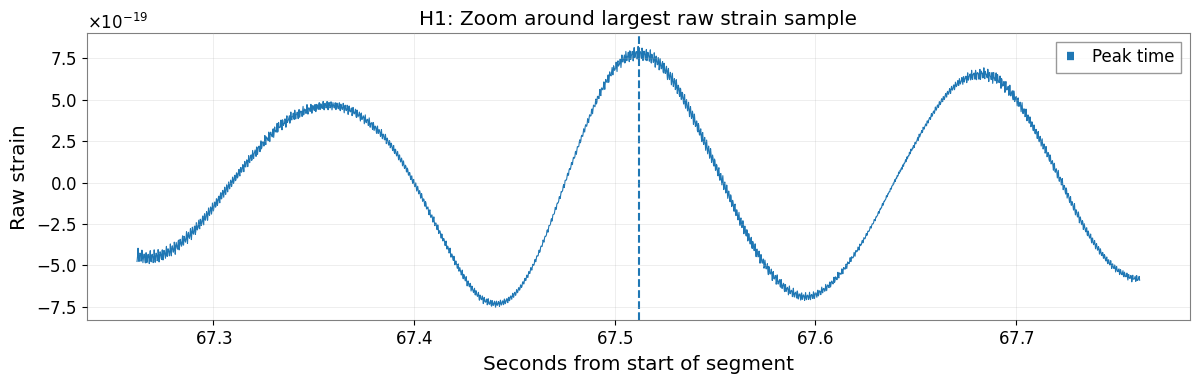

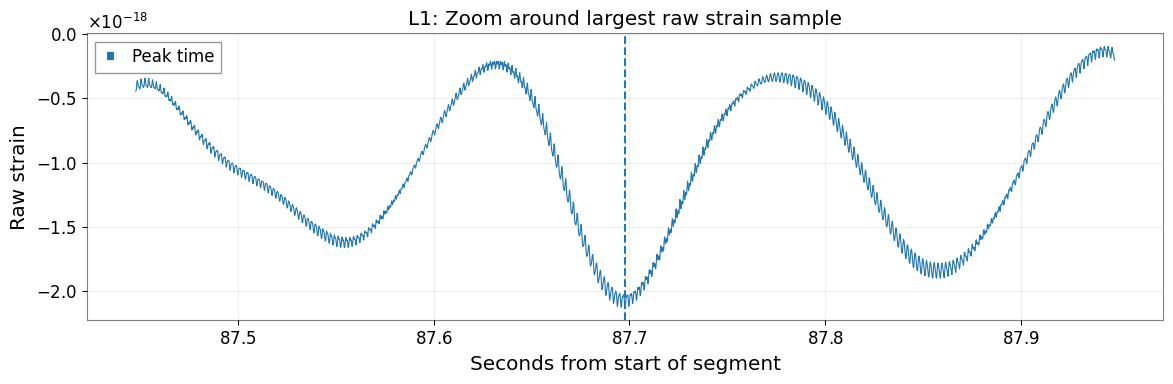

In [ ]:


def plot_peak(data, detector, peak_time, fs, half_width=0.25):
    center = int(peak_time * fs)
    radius = int(half_width * fs)

    start = max(0, center - radius)
    end = min(len(data), center + radius)

    times = np.arange(start, end) / fs

    plt.figure(figsize=(12, 4))
    plt.plot(times, data[start:end], linewidth=0.8)
    plt.axvline(peak_time, linestyle="--", label="Peak time")
    plt.title(f"{detector}: Zoom around largest raw strain sample")
    plt.xlabel("Seconds from start of segment")
    plt.ylabel("Raw strain")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_peak(h1_noise_data, "H1", 67.512, noise_fs_h1)
plot_peak(l1_noise_data, "L1", 87.698, noise_fs_l1)


# Check the local peaks and surrounding data

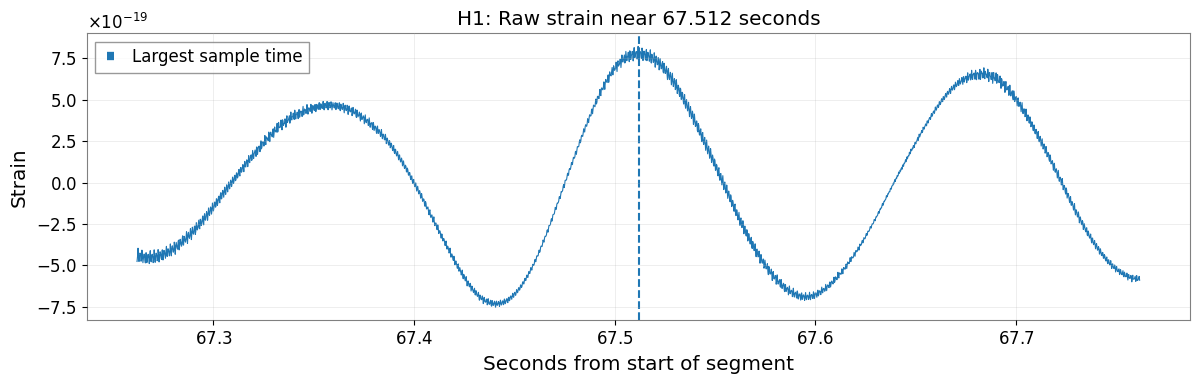

H1 local maximum absolute strain: 8.2225e-19
H1 local standard deviation: 4.5551e-19


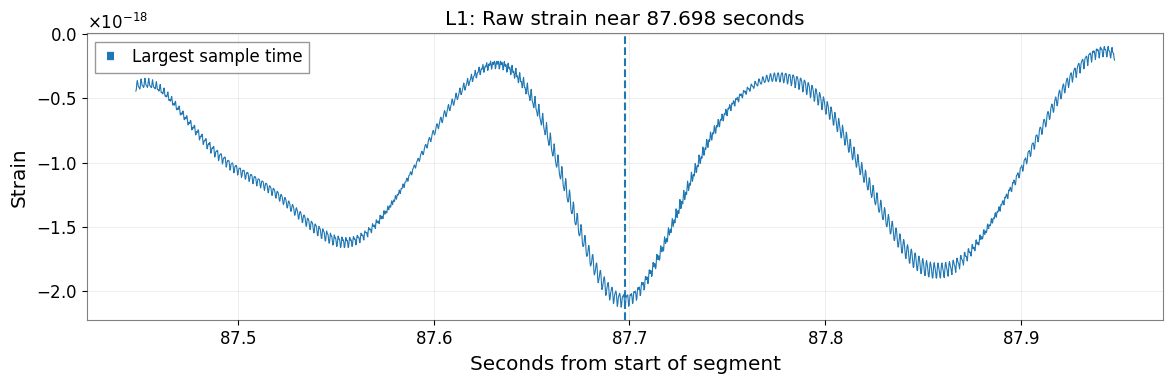

L1 local maximum absolute strain: 2.1232e-18
L1 local standard deviation: 5.4881e-19


In [ ]:

def inspect_peak(data, detector, peak_time, fs):
    center = int(round(peak_time * fs))
    radius = int(0.25 * fs)  # 0.25 seconds on each side

    start = max(0, center - radius)
    end = min(len(data), center + radius)

    times = np.arange(start, end) / fs
    segment = data[start:end]

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(times, segment, linewidth=0.8)
    ax.axvline(peak_time, linestyle="--", label="Largest sample time")
    ax.set_title(f"{detector}: Raw strain near {peak_time:.3f} seconds")
    ax.set_xlabel("Seconds from start of segment")
    ax.set_ylabel("Strain")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    print(f"{detector} local maximum absolute strain: {np.max(np.abs(segment)):.4e}")
    print(f"{detector} local standard deviation: {np.std(segment):.4e}")

inspect_peak(h1_noise_data, "H1", 67.512, noise_fs_h1)
inspect_peak(l1_noise_data, "L1", 87.698, noise_fs_l1)


In [ ]:
def compare_peak_region(data, detector, peak_time, fs, width=0.5):
    center = int(round(peak_time * fs))
    radius = int(width * fs / 2)

    start = max(0, center - radius)
    end = min(len(data), center + radius)

    local = data[start:end]
    full_std = np.std(data)
    local_std = np.std(local)

    print(f"\n{detector}")
    print(f"Full-segment standard deviation: {full_std:.4e}")
    print(f"Local standard deviation:        {local_std:.4e}")
    print(f"Local/full variability ratio:    {local_std / full_std:.2f}")
    print(f"Local maximum absolute strain:   {np.max(np.abs(local)):.4e}")

compare_peak_region(h1_noise_data, "H1", 67.512, noise_fs_h1)
compare_peak_region(l1_noise_data, "L1", 87.698, noise_fs_l1)



H1
Full-segment standard deviation: 2.0188e-19
Local standard deviation:        4.5551e-19
Local/full variability ratio:    2.26
Local maximum absolute strain:   8.2225e-19

L1
Full-segment standard deviation: 2.3255e-19
Local standard deviation:        5.4881e-19
Local/full variability ratio:    2.36
Local maximum absolute strain:   2.1232e-18


Filtered H1 standard deviation: 1.3074357182770319e-21
Filtered L1 standard deviation: 3.2640758243367072e-21
H1 finite: True
L1 finite: True


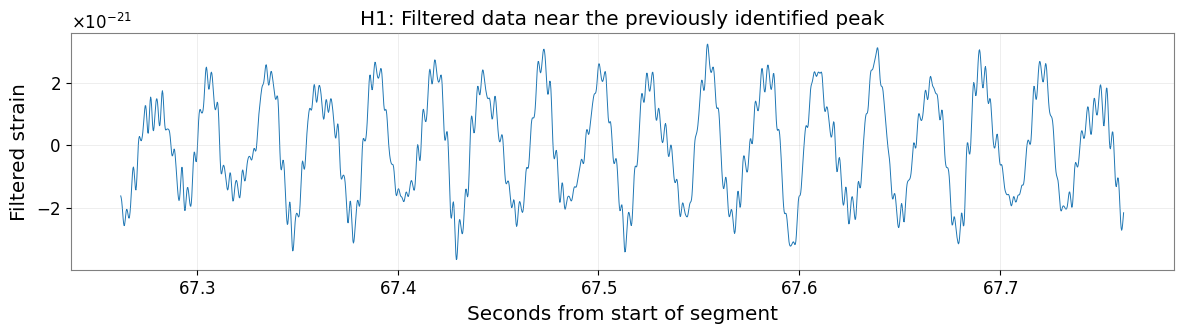

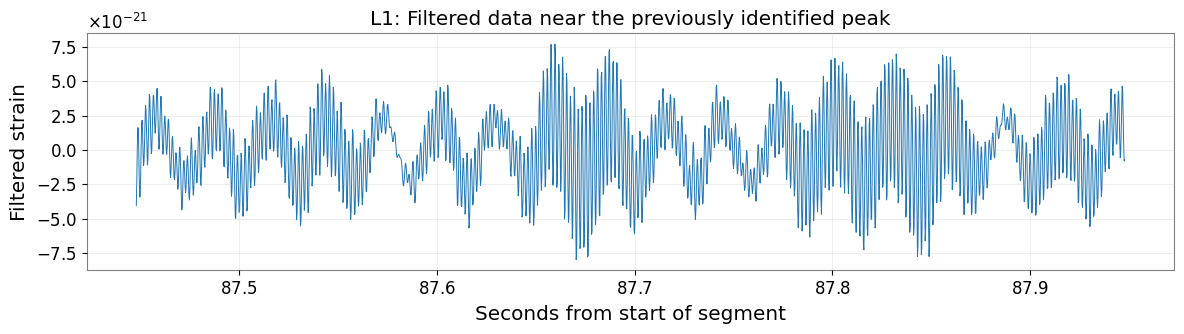

In [ ]:
from scipy.signal import butter, sosfiltfilt
from pycbc.psd import interpolate, inverse_spectrum_truncation
from pycbc.waveform import get_fd_waveform
from pycbc.filter import matched_filter


# Apply the same frequency band used in the existing analysis
sos = butter(
    4,
    [30, 400],
    btype="bandpass",
    fs=int(noise_fs_h1),
    output="sos"
)

h1_noise_filtered = sosfiltfilt(sos, h1_noise_data)
l1_noise_filtered = sosfiltfilt(sos, l1_noise_data)

print("Filtered H1 standard deviation:", np.std(h1_noise_filtered))
print("Filtered L1 standard deviation:", np.std(l1_noise_filtered))
print("H1 finite:", np.isfinite(h1_noise_filtered).all())
print("L1 finite:", np.isfinite(l1_noise_filtered).all())

def plot_filtered_peak(data, detector, center_time, fs):
    radius = int(0.25 * fs)
    center = int(round(center_time * fs))
    start = max(0, center - radius)
    end = min(len(data), center + radius)
    times = np.arange(start, end) / fs

    plt.figure(figsize=(12, 3.5))
    plt.plot(times, data[start:end], linewidth=0.7)
    plt.title(f"{detector}: Filtered data near the previously identified peak")
    plt.xlabel("Seconds from start of segment")
    plt.ylabel("Filtered strain")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_filtered_peak(h1_noise_filtered, "H1", 67.512, noise_fs_h1)
plot_filtered_peak(l1_noise_filtered, "L1", 87.698, noise_fs_l1)


## Create candidate one-second windows

In [ ]:

fs = int(noise_fs_h1)
window_samples = fs  # 1 second at 4096 Hz

# Keep only complete, aligned one-second windows
usable = (min(len(h1_noise_filtered), len(l1_noise_filtered))
          // window_samples) * window_samples

h1_windows = h1_noise_filtered[:usable].reshape(-1, window_samples)
l1_windows = l1_noise_filtered[:usable].reshape(-1, window_samples)

# Shape: (number of windows, samples per second, detectors)
X_noise_candidates = np.stack(
    [h1_windows, l1_windows],
    axis=-1
).astype(np.float32)

print("Candidate window dataset shape:", X_noise_candidates.shape)
print("Window duration: 1 second")
print("Number of candidate windows:", len(X_noise_candidates))
print("Samples per detector per window:", window_samples)
print("All values finite:", np.isfinite(X_noise_candidates).all())


Candidate window dataset shape: (128, 4096, 2)
Window duration: 1 second
Number of candidate windows: 128
Samples per detector per window: 4096
All values finite: True


Waveform model: IMRPhenomD
Sample rate: 4096 Hz
Waveform duration: 16.0 seconds
Plus polarization peak: 1.3457448e-21
Cross polarization peak: 1.3366326e-21
All waveform values finite: True


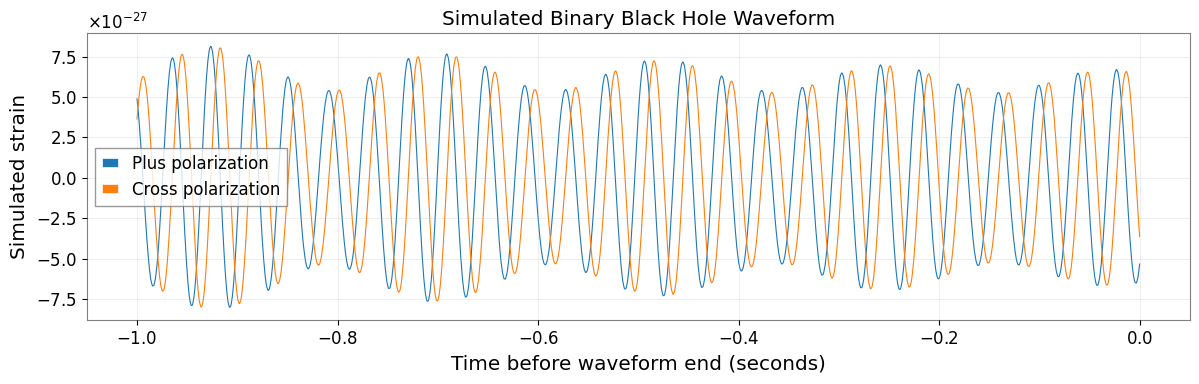

In [ ]:
from pycbc.waveform import get_td_waveform
from pycbc.types import TimeSeries
from pycbc.psd import interpolate, inverse_spectrum_truncation
from pycbc.filter import matched_filter
from pycbc.detector import Detector


fs = 4096

# Illustrative binary-black-hole parameters
hp, hc = get_td_waveform(
    approximant="IMRPhenomD",
    mass1=35,
    mass2=30,
    distance=500,       # Mpc
    inclination=0.5,    # radians
    coa_phase=0,
    delta_t=1 / fs,
    f_lower=30
)

hp_data = np.asarray(hp, dtype=np.float32)
hc_data = np.asarray(hc, dtype=np.float32)

print("Waveform model: IMRPhenomD")
print("Sample rate:", fs, "Hz")
print("Waveform duration:", len(hp_data) / fs, "seconds")
print("Plus polarization peak:", np.max(np.abs(hp_data)))
print("Cross polarization peak:", np.max(np.abs(hc_data)))
print("All waveform values finite:",
      np.isfinite(hp_data).all() and np.isfinite(hc_data).all())

# Plot the final second, where the merger occurs
n_show = min(fs, len(hp_data))
time_to_merger = np.arange(-n_show, 0) / fs

plt.figure(figsize=(12, 4))
plt.plot(time_to_merger, hp_data[-n_show:], linewidth=0.8,
         label="Plus polarization")
plt.plot(time_to_merger, hc_data[-n_show:], linewidth=0.8,
         label="Cross polarization")
plt.xlabel("Time before waveform end (seconds)")
plt.ylabel("Simulated strain")
plt.title("Simulated Binary Black Hole Waveform")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Inspect the waveform around merger

Peak sample index: 45038
Peak time from waveform start: 10.995605 seconds
Time remaining after peak: 5.004150 seconds


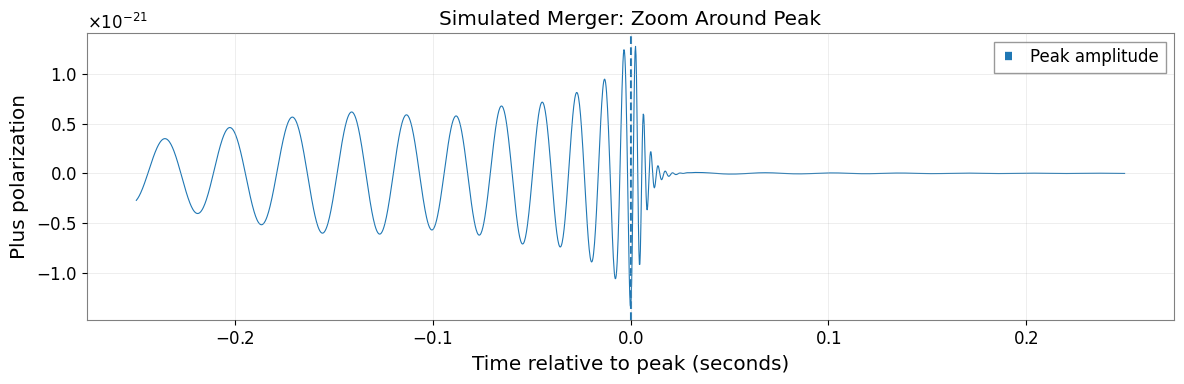

In [ ]:

# Find the peak amplitude of the plus polarization
peak_index = int(np.argmax(np.abs(hp_data)))
peak_time = peak_index / fs

print("Peak sample index:", peak_index)
print("Peak time from waveform start:", f"{peak_time:.6f} seconds")
print("Time remaining after peak:",
      f"{(len(hp_data) - 1 - peak_index) / fs:.6f} seconds")

# Display a half-second window centered on the peak
half_window = fs // 4
start = max(0, peak_index - half_window)
end = min(len(hp_data), peak_index + half_window)

t_local = (np.arange(start, end) - peak_index) / fs

plt.figure(figsize=(12, 4))
plt.plot(t_local, hp_data[start:end], linewidth=0.8)
plt.axvline(0, linestyle="--", label="Peak amplitude")
plt.xlabel("Time relative to peak (seconds)")
plt.ylabel("Plus polarization")
plt.title("Simulated Merger: Zoom Around Peak")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Extracted plus window shape: (4096,)
Extracted cross window shape: (4096,)
Window duration: 1.0 seconds
Peak position in window: 0.5 seconds
Plus-window peak: 1.3457448e-21
Cross-window peak: 1.3366326e-21


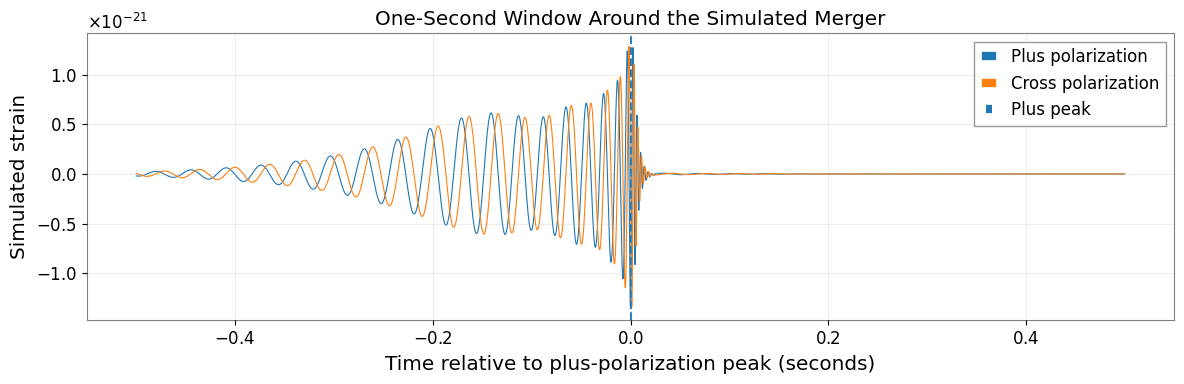

In [ ]:
# Extract one second centered on the plus-polarization peak
window_samples = fs
half = window_samples // 2

start = peak_index - half
end = start + window_samples

assert start >= 0 and end <= len(hp_data)

hp_window = hp_data[start:end].copy()
hc_window = hc_data[start:end].copy()

t_window = (np.arange(window_samples) - half) / fs

print("Extracted plus window shape:", hp_window.shape)
print("Extracted cross window shape:", hc_window.shape)
print("Window duration:", len(hp_window) / fs, "seconds")
print("Peak position in window:", half / fs, "seconds")
print("Plus-window peak:", np.max(np.abs(hp_window)))
print("Cross-window peak:", np.max(np.abs(hc_window)))

plt.figure(figsize=(12, 4))
plt.plot(t_window, hp_window, label="Plus polarization", linewidth=0.8)
plt.plot(t_window, hc_window, label="Cross polarization", linewidth=0.8)
plt.axvline(0, linestyle="--", label="Plus peak")
plt.xlabel("Time relative to plus-polarization peak (seconds)")
plt.ylabel("Simulated strain")
plt.title("One-Second Window Around the Simulated Merger")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Calculate the H1 and L1 detector responses

In [ ]:
print("PyCBC Detector class:", Detector)

try:
    print("\nDetector response method signature:")
    print(inspect.signature(Detector.project_wave))
    print("\nDetector time-delay method signature:")
    print(inspect.signature(Detector.time_delay_from_earth_center))
except Exception as exc:
    print("Could not inspect detector methods:", repr(exc))


PyCBC Detector class: <class 'pycbc.detector.ground.Detector'>

Detector response method signature:
(self, hp, hc, ra, dec, polarization, method='lal', reference_time=None)

Detector time-delay method signature:
(self, right_ascension, declination, t_gps)


## Project the waveform into H1 and L1

In [ ]:
# Illustrative source position, in radians
ra = 1.2
dec = 0.4
polarization = 0.7
reference_gps = 1126259462

# Convert NumPy arrays into PyCBC time series
hp_ts = TimeSeries(
    hp_data.astype(np.float64),
    delta_t=1 / fs,
    epoch=reference_gps
)
hc_ts = TimeSeries(
    hc_data.astype(np.float64),
    delta_t=1 / fs,
    epoch=reference_gps
)

det_h1 = Detector("H1")
det_l1 = Detector("L1")

h1_response = det_h1.project_wave(
    hp_ts, hc_ts, ra, dec, polarization,
    method="lal"
)

l1_response = det_l1.project_wave(
    hp_ts, hc_ts, ra, dec, polarization,
    method="lal"
)

h1_response = np.asarray(h1_response, dtype=np.float32)
l1_response = np.asarray(l1_response, dtype=np.float32)

delay = (
    det_l1.time_delay_from_earth_center(ra, dec, reference_gps)
    - det_h1.time_delay_from_earth_center(ra, dec, reference_gps)
)

print("H1 response shape:", h1_response.shape)
print("L1 response shape:", l1_response.shape)
print("H1 response peak:", np.max(np.abs(h1_response)))
print("L1 response peak:", np.max(np.abs(l1_response)))
print("L1 minus H1 geometric delay:", delay, "seconds")
print(
    "All response values finite:",
    np.isfinite(h1_response).all()
    and np.isfinite(l1_response).all()
)


H1 response shape: (65603,)
L1 response shape: (65603,)
H1 response peak: 9.531789e-22
L1 response peak: 1.2718682e-21
L1 minus H1 geometric delay: -0.005049654796263027 seconds
All response values finite: True


In [ ]:


print("Original waveform")
print("  Sample rate:", fs, "Hz")
print("  Samples:", len(hp_data))
print("  Duration:", len(hp_data) / fs, "seconds")
print("  Start GPS:", float(hp_ts.start_time))

print("\nProjected responses")
print("  H1 type:", type(h1_response).__name__)
print("  H1 samples:", len(h1_response))
print("  H1 duration at 4096 Hz:", len(h1_response) / fs, "seconds")
print("  L1 samples:", len(l1_response))
print("  L1 duration at 4096 Hz:", len(l1_response) / fs, "seconds")

print("\nTiming reference")
print("  Reference GPS:", reference_gps)
print("  L1 minus H1 geometric delay:", f"{delay:.6f} seconds")

assert len(h1_response) == len(l1_response)
assert np.isfinite(h1_response).all()
assert np.isfinite(l1_response).all()


Original waveform
  Sample rate: 4096 Hz
  Samples: 65536
  Duration: 16.0 seconds
  Start GPS: 1126259462.0

Projected responses
  H1 type: ndarray
  H1 samples: 65603
  H1 duration at 4096 Hz: 16.016357421875 seconds
  L1 samples: 65603
  L1 duration at 4096 Hz: 16.016357421875 seconds

Timing reference
  Reference GPS: 1126259462
  L1 minus H1 geometric delay: -0.005050 seconds


In [ ]:

hp_ts = TimeSeries(
    hp_data.astype(np.float64),
    delta_t=1 / fs,
    epoch=reference_gps
)
hc_ts = TimeSeries(
    hc_data.astype(np.float64),
    delta_t=1 / fs,
    epoch=reference_gps
)

det_h1 = Detector("H1")
det_l1 = Detector("L1")

h1_projected_ts = det_h1.project_wave(
    hp_ts, hc_ts, ra, dec, polarization,
    method="lal"
)
l1_projected_ts = det_l1.project_wave(
    hp_ts, hc_ts, ra, dec, polarization,
    method="lal"
)

for name, series in [
    ("H1", h1_projected_ts),
    ("L1", l1_projected_ts)
]:
    print(f"\n{name}")
    print("Type:", type(series).__name__)
    print("Samples:", len(series))
    print("Start GPS:", float(series.start_time))
    print("End GPS:", float(series.end_time))
    print("Sample rate:", float(series.sample_rate), "Hz")



H1
Type: TimeSeries
Samples: 65603
Start GPS: 1126259461.9768066
End GPS: 1126259477.993164
Sample rate: 4096.0 Hz

L1
Type: TimeSeries
Samples: 65603
Start GPS: 1126259461.9716797
End GPS: 1126259477.988037
Sample rate: 4096.0 Hz


## Locate the merger peak in each detector

In [ ]:
h1_projected_data = np.asarray(h1_projected_ts, dtype=np.float64)
l1_projected_data = np.asarray(l1_projected_ts, dtype=np.float64)

h1_start_gps = float(h1_projected_ts.start_time)
l1_start_gps = float(l1_projected_ts.start_time)

h1_peak_idx = int(np.argmax(np.abs(h1_projected_data)))
l1_peak_idx = int(np.argmax(np.abs(l1_projected_data)))

h1_peak_gps = h1_start_gps + h1_peak_idx / fs
l1_peak_gps = l1_start_gps + l1_peak_idx / fs

print("H1 projected peak GPS:", f"{h1_peak_gps:.6f}")
print("L1 projected peak GPS:", f"{l1_peak_gps:.6f}")
print("L1 minus H1 peak time:", f"{l1_peak_gps - h1_peak_gps:.6f}", "seconds")

print("\nPeak amplitudes")
print("H1:", f"{np.max(np.abs(h1_projected_data)):.4e}")
print("L1:", f"{np.max(np.abs(l1_projected_data)):.4e}")

print("\nBoth series have matching sample rates:",
      h1_projected_ts.sample_rate == l1_projected_ts.sample_rate)


H1 projected peak GPS: 1126259472.981689
L1 projected peak GPS: 1126259472.976562
L1 minus H1 peak time: -0.005127 seconds

Peak amplitudes
H1: 9.5318e-22
L1: 1.2719e-21

Both series have matching sample rates: True


In [ ]:
# Check the time coverage and peak locations of both projected signals.

h1_end_gps = float(h1_projected_ts.end_time)
l1_end_gps = float(l1_projected_ts.end_time)

print("H1 projected signal")
print("  Samples:", len(h1_projected_data))
print("  Start GPS:", f"{h1_start_gps:.6f}")
print("  End GPS:", f"{h1_end_gps:.6f}")
print("  Duration:", f"{len(h1_projected_data) / fs:.3f} seconds")
print("  Peak index:", h1_peak_idx)

print("\nL1 projected signal")
print("  Samples:", len(l1_projected_data))
print("  Start GPS:", f"{l1_start_gps:.6f}")
print("  End GPS:", f"{l1_end_gps:.6f}")
print("  Duration:", f"{len(l1_projected_data) / fs:.3f} seconds")
print("  Peak index:", l1_peak_idx)

print("\nTiming difference between series starts:",
      f"{l1_start_gps - h1_start_gps:.6f} seconds")

H1 projected signal
  Samples: 65603
  Start GPS: 1126259461.976807
  End GPS: 1126259477.993164
  Duration: 16.016 seconds
  Peak index: 45076

L1 projected signal
  Samples: 65603
  Start GPS: 1126259461.971680
  End GPS: 1126259477.988037
  Duration: 16.016 seconds
  Peak index: 45076

Timing difference between series starts: -0.005127 seconds


## Build the AI training dataset

In [ ]:
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)

# 1. Put both simulated detector responses on one shared time grid.
template_times = h1_peak_gps + np.arange(-window_samples // 2,
                                          window_samples // 2) / fs

h1_projected_times = h1_start_gps + np.arange(len(h1_projected_data)) / fs
l1_projected_times = l1_start_gps + np.arange(len(l1_projected_data)) / fs

h1_template = np.interp(
    template_times, h1_projected_times, h1_projected_data
)
l1_template = np.interp(
    template_times, l1_projected_times, l1_projected_data
)

signal_template = np.stack([h1_template, l1_template], axis=-1)

# 2. Scale each detector channel using its background standard deviation.
channel_scales = np.std(X_noise_candidates, axis=(0, 1))
channel_scales = np.maximum(channel_scales, 1e-30)

noise_windows = X_noise_candidates / channel_scales
signal_template = signal_template / channel_scales

# 3. Split original windows BEFORE creating augmented examples.
indices = np.arange(len(noise_windows))
train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=42
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=42
)

# 4. Make noise-only and injected versions of each window.
def make_examples(base_indices, repeats=12):
    examples, labels = [], []

    for idx in base_indices:
        background = noise_windows[idx]

        for _ in range(repeats):
            examples.append(background.copy())
            labels.append(0)

            strength = rng.uniform(0.5, 3.0)
            injected = background + strength * signal_template
            examples.append(injected.astype(np.float32))
            labels.append(1)

    order = rng.permutation(len(labels))
    return (
        np.asarray(examples, dtype=np.float32)[order],
        np.asarray(labels, dtype=np.int32)[order]
    )

X_train, y_train = make_examples(train_idx)
X_val, y_val = make_examples(val_idx)
X_test, y_test = make_examples(test_idx)

print("Training:", X_train.shape, "| positive fraction:", round(y_train.mean(), 3))
print("Validation:", X_val.shape, "| positive fraction:", round(y_val.mean(), 3))
print("Test:", X_test.shape, "| positive fraction:", round(y_test.mean(), 3))
print("All inputs finite:", all(np.isfinite(x).all()
      for x in [X_train, X_val, X_test]))

Training: (2136, 4096, 2) | positive fraction: 0.5
Validation: (456, 4096, 2) | positive fraction: 0.5
Test: (480, 4096, 2) | positive fraction: 0.5
All inputs finite: True


## Build and train the 1D CNN

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
import os

tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    layers.Input(shape=(4096, 2)),

    layers.Conv1D(16, kernel_size=15, strides=2, padding="same",
                 activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=4),

    layers.Conv1D(32, kernel_size=9, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=4),

    layers.Conv1D(64, kernel_size=7, padding="same", activation="relu"),
    layers.GlobalAveragePooling1D(),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=12,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

print("\nTest-set evaluation:")
model.evaluate(X_test, y_test, verbose=1)

Epoch 1/12
67/67 ━━━━━━━━━━━━━━━━━━━━ 17s 205ms/step - accuracy: 0.6531 - loss: 0.6289 - precision: 0.6401 - recall: 0.6994 - val_accuracy: 0.5504 - val_loss: 0.6820 - val_precision: 0.7447 - val_recall: 0.1535
Epoch 2/12
67/67 ━━━━━━━━━━━━━━━━━━━━ 12s 179ms/step - accuracy: 0.8848 - loss: 0.3243 - precision: 0.9272 - recall: 0.8352 - val_accuracy: 0.5066 - val_loss: 0.7005 - val_precision: 1.0000 - val_recall: 0.0132
Epoch 3/12
67/67 ━━━━━━━━━━━━━━━━━━━━ 12s 177ms/step - accuracy: 0.9504 - loss: 0.1523 - precision: 0.9791 - recall: 0.9204 - val_accuracy: 0.7390 - val_loss: 0.5282 - val_precision: 1.0000 - val_recall: 0.4781
Epoch 4/12
67/67 ━━━━━━━━━━━━━━━━━━━━ 14s 82ms/step - accuracy: 0.9813 - loss: 0.0774 - precision: 0.9971 - recall: 0.9654 - val_accuracy: 0.8531 - val_loss: 0.3671 - val_precision: 1.0000 - val_recall: 0.7061
Epoch 5/12
67/67 ━━━━━━━━━━━━━━━━━━━━ 7s 102ms/step - accuracy: 0.9864 - loss: 0.0461 - precision: 0.9971 - recall: 0.9757 - val_accuracy: 0.9254 - val_loss:

[0.1928359568119049, 0.925000011920929, 1.0, 0.8500000238418579]

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Generate probabilities and classify at a threshold of 0.5
test_probabilities = model.predict(X_test, verbose=0).ravel()
test_predictions = (test_probabilities >= 0.5).astype(int)

print("Confusion matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Noise-only", "Injected signal"],
    digits=3
))

# Save the trained model
model.save("gw_cnn_prototype.keras")

print("\nSaved model: gw_cnn_prototype.keras")
print("Test examples:", len(y_test))
print("Mean predicted probability:", round(float(test_probabilities.mean()), 4))

Confusion matrix:
[[240   0]
 [ 36 204]]

Classification report:
                 precision    recall  f1-score   support

     Noise-only      0.870     1.000     0.930       240
Injected signal      1.000     0.850     0.919       240

       accuracy                          0.925       480
      macro avg      0.935     0.925     0.925       480
   weighted avg      0.935     0.925     0.925       480


Saved model: gw_cnn_prototype.keras
Test examples: 480
Mean predicted probability: 0.4303


In [ ]:

model_path = "gw_cnn_prototype.keras"

assert os.path.exists(model_path), "Model file not found."

loaded_model = tf.keras.models.load_model(model_path)

print("Model loaded successfully.")
print("Input shape:", loaded_model.input_shape)
print("Output shape:", loaded_model.output_shape)
print("Model file size:", round(os.path.getsize(model_path) / 1024**2, 2), "MB")

Model loaded successfully.
Input shape: (None, 4096, 2)
Output shape: (None, 1)
Model file size: 0.3 MB


In [ ]:
# Three additional stretches, separate from the original background.
offsets = [600, 900, 1200]
extra_backgrounds = []

for offset in offsets:
    start = gps_event - offset
    end = start + 128

    print(f"Fetching background: GPS {start} to {end}")

    h1 = GWpyTimeSeries.fetch_open_data(
        "H1", start, end, cache=False
    )
    l1 = GWpyTimeSeries.fetch_open_data(
        "L1", start, end, cache=False
    )

    h1_arr = np.asarray(h1.value, dtype=np.float64)
    l1_arr = np.asarray(l1.value, dtype=np.float64)

    if len(h1_arr) != len(l1_arr):
        raise ValueError("H1/L1 sample counts do not match.")
    if not (np.isfinite(h1_arr).all() and np.isfinite(l1_arr).all()):
        raise ValueError("Non-finite samples found; inspect this segment.")

    h1_f = sosfiltfilt(sos, h1_arr)
    l1_f = sosfiltfilt(sos, l1_arr)

    extra_backgrounds.append(
        np.stack([h1_f, l1_f], axis=-1).astype(np.float32)
    )

print("\nAdditional segments downloaded:", len(extra_backgrounds))
print("Samples per segment:", [x.shape for x in extra_backgrounds])
print("All finite:", all(np.isfinite(x).all() for x in extra_backgrounds))

Fetching background: GPS 1126258862 to 1126258990
Fetching background: GPS 1126258562 to 1126258690
Fetching background: GPS 1126258262 to 1126258390

Additional segments downloaded: 3
Samples per segment: [(524288, 2), (524288, 2), (524288, 2)]
All finite: True


## Build a segment-separated dataset

In [ ]:

rng = np.random.default_rng(42)

# Original segment plus the three newly downloaded segments.
background_segments = [
    X_noise_candidates.reshape(128, 4096, 2),
    *[
        segment.reshape(128, 4096, 2)
        for segment in extra_backgrounds
    ]
]

# Split by WHOLE segment to reduce data leakage.
train_segments = background_segments[:2]
val_segments   = background_segments[2:3]
test_segments  = background_segments[3:4]

# Use the same channel scaling as the original prototype.
def build_segment_dataset(segments):
    examples, labels = [], []

    for segment in segments:
        for window in segment:
            noise = window / channel_scales

            # Noise-only example.
            examples.append(noise.copy())
            labels.append(0)

            # Inject the simulated two-detector template.
            # Random shifts prevent every signal appearing at the
            # exact same sample position.
            shift = int(rng.integers(-int(0.15 * fs), int(0.15 * fs) + 1))
            shifted = np.zeros_like(signal_template)

            if shift > 0:
                shifted[shift:] = signal_template[:-shift]
            elif shift < 0:
                shifted[:shift] = signal_template[-shift:]
            else:
                shifted[:] = signal_template

            strength = rng.uniform(0.5, 3.0)
            examples.append((noise + strength * shifted).astype(np.float32))
            labels.append(1)

    order = rng.permutation(len(labels))
    return (
        np.asarray(examples, dtype=np.float32)[order],
        np.asarray(labels, dtype=np.int32)[order]
    )

X_train, y_train = build_segment_dataset(train_segments)
X_val, y_val = build_segment_dataset(val_segments)
X_test, y_test = build_segment_dataset(test_segments)

print("Training:", X_train.shape, "Positive fraction:", y_train.mean())
print("Validation:", X_val.shape, "Positive fraction:", y_val.mean())
print("Test:", X_test.shape, "Positive fraction:", y_test.mean())
print("Segment separation: train=2, validation=1, test=1")
print("All finite:", all(
    np.isfinite(x).all() for x in [X_train, X_val, X_test]
))

Training: (512, 4096, 2) Positive fraction: 0.5
Validation: (256, 4096, 2) Positive fraction: 0.5
Test: (256, 4096, 2) Positive fraction: 0.5
Segment separation: train=2, validation=1, test=1
All finite: True


In [ ]:
tf.keras.utils.set_random_seed(42)

improved_model = models.Sequential([
    layers.Input(shape=(4096, 2)),
    layers.Conv1D(16, 15, strides=2, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(4),

    layers.Conv1D(32, 9, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(4),

    layers.Conv1D(64, 7, padding="same", activation="relu"),
    layers.GlobalAveragePooling1D(),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_improved = improved_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=12,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

print("\nHeld-out segment test results:")
test_results = improved_model.evaluate(X_test, y_test, verbose=1)

improved_model.save("gw_cnn_segment_split.keras")
print("\nSaved: gw_cnn_segment_split.keras")

Epoch 1/12
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 210ms/step - accuracy: 0.5059 - loss: 0.7319 - precision: 0.5046 - recall: 0.6367 - val_accuracy: 0.5000 - val_loss: 0.6924 - val_precision: 0.5000 - val_recall: 1.0000
Epoch 2/12
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 149ms/step - accuracy: 0.5332 - loss: 0.6931 - precision: 0.5368 - recall: 0.4844 - val_accuracy: 0.5000 - val_loss: 0.6921 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/12
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 239ms/step - accuracy: 0.5918 - loss: 0.6804 - precision: 0.5959 - recall: 0.5703 - val_accuracy: 0.5000 - val_loss: 0.6912 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/12
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 140ms/step - accuracy: 0.6270 - loss: 0.6711 - precision: 0.6217 - recall: 0.6484 - val_accuracy: 0.5000 - val_loss: 0.6923 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 5/12
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.6328 - loss: 0.6538 - precision: 0.6360 - recall: 0.6211 - val_accuracy

In [ ]:
print("Template peak / channel:", np.max(np.abs(signal_template), axis=0))
print("Template RMS / channel:", np.sqrt(np.mean(signal_template**2, axis=0)))

test_noise = X_test[y_test == 0]
test_injected = X_test[y_test == 1]

print("\nHeld-out noise RMS per channel:",
      np.sqrt(np.mean(test_noise**2, axis=(0, 1))))
print("Held-out injected RMS per channel:",
      np.sqrt(np.mean(test_injected**2, axis=(0, 1))))

prob = improved_model.predict(X_test, verbose=0).ravel()
print("\nPredicted probability range:",
      float(prob.min()), "to", float(prob.max()))
print("Mean probability for noise:",
      float(prob[y_test == 0].mean()))
print("Mean probability for injected examples:",
      float(prob[y_test == 1].mean()))

Template peak / channel: [0.7290028  0.38968425]
Template RMS / channel: [0.1297929  0.06916758]

Held-out noise RMS per channel: [0.9976731 0.8010527]
Held-out injected RMS per channel: [1.0305007  0.81260663]

Predicted probability range: 0.4737907648086548 to 0.4923239052295685
Mean probability for noise: 0.4814680814743042
Mean probability for injected examples: 0.4843396544456482


## Train with a range of stronger injections

In [ ]:
rng = np.random.default_rng(123)

def make_diagnostic_dataset(segments, repeats=4):
    X, y = [], []

    for segment in segments:
        for window in segment:
            noise = window / channel_scales

            for _ in range(repeats):
                X.append(noise.copy())
                y.append(0)

                shift = int(rng.integers(-int(0.15 * fs), int(0.15 * fs) + 1))
                shifted = np.zeros_like(signal_template)

                if shift > 0:
                    shifted[shift:] = signal_template[:-shift]
                elif shift < 0:
                    shifted[:shift] = signal_template[-shift:]
                else:
                    shifted[:] = signal_template

                # Diagnostic strengths, deliberately larger than before.
                strength = rng.uniform(5.0, 15.0)
                X.append((noise + strength * shifted).astype(np.float32))
                y.append(1)

    order = rng.permutation(len(y))
    return np.asarray(X)[order], np.asarray(y, dtype=np.int32)[order]

X_train_diag, y_train_diag = make_diagnostic_dataset(train_segments)
X_val_diag, y_val_diag = make_diagnostic_dataset(val_segments)
X_test_diag, y_test_diag = make_diagnostic_dataset(test_segments)

tf.keras.utils.set_random_seed(123)

diagnostic_model = models.Sequential([
    layers.Input(shape=(4096, 2)),
    layers.Conv1D(16, 15, strides=2, padding="same", activation="relu"),
    layers.MaxPooling1D(4),
    layers.Conv1D(32, 9, padding="same", activation="relu"),
    layers.MaxPooling1D(4),
    layers.Conv1D(64, 7, padding="same", activation="relu"),
    layers.GlobalAveragePooling1D(),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

diagnostic_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

diagnostic_model.fit(
    X_train_diag, y_train_diag,
    validation_data=(X_val_diag, y_val_diag),
    epochs=8,
    batch_size=32,
    callbacks=[callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    )],
    verbose=1
)

print("\nHeld-out diagnostic evaluation:")
diagnostic_model.evaluate(X_test_diag, y_test_diag, verbose=1)

Epoch 1/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 214ms/step - accuracy: 0.7690 - loss: 0.4837 - val_accuracy: 0.5586 - val_loss: 0.5996
Epoch 2/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 14s 214ms/step - accuracy: 0.9565 - loss: 0.1346 - val_accuracy: 0.9180 - val_loss: 0.2141
Epoch 3/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 17s 155ms/step - accuracy: 0.9907 - loss: 0.0349 - val_accuracy: 0.9961 - val_loss: 0.0467
Epoch 4/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 8s 127ms/step - accuracy: 0.9976 - loss: 0.0126 - val_accuracy: 1.0000 - val_loss: 0.0221
Epoch 5/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 10s 131ms/step - accuracy: 0.9995 - loss: 0.0051 - val_accuracy: 1.0000 - val_loss: 0.0030
Epoch 6/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 86ms/step - accuracy: 1.0000 - loss: 0.0033 - val_accuracy: 1.0000 - val_loss: 0.0019
Epoch 7/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 1.0000 - val_loss: 0.0029
Epoch 8/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 1.0000 - loss: 0.0024 - val_accuracy: 1.0000 - 

[0.0016773021779954433, 1.0]

In [ ]:
diagnostic_model.save("gw_cnn_strong_injection_diagnostic.keras")

test_probs = diagnostic_model.predict(X_test_diag, verbose=0).ravel()
test_preds = (test_probs >= 0.5).astype(int)

diagnostic_results = {
    "experiment": "strong_injection_diagnostic",
    "test_accuracy": float(np.mean(test_preds == y_test_diag)),
    "test_size": int(len(y_test_diag)),
    "confusion_matrix": confusion_matrix(
        y_test_diag, test_preds
    ).tolist(),
    "injection_strength_range": [5.0, 15.0],
    "background_segments": 4,
    "limitation": (
        "Strong synthetic injections; simplified one-second template; "
        "not a validated real-world gravitational-wave detector."
    )
}

with open("gw_cnn_diagnostic_results.json", "w") as f:
    json.dump(diagnostic_results, f, indent=2)

print(json.dumps(diagnostic_results, indent=2))
print("\nSaved model:", os.path.getsize(
    "gw_cnn_strong_injection_diagnostic.keras"
) / 1024**2, "MB")
print("Saved results: gw_cnn_diagnostic_results.json")

{
  "experiment": "strong_injection_diagnostic",
  "test_accuracy": 1.0,
  "test_size": 1024,
  "confusion_matrix": [
    [
      512,
      0
    ],
    [
      0,
      512
    ]
  ],
  "injection_strength_range": [
    5.0,
    15.0
  ],
  "background_segments": 4,
  "limitation": "Strong synthetic injections; simplified one-second template; not a validated real-world gravitational-wave detector."
}

Saved model: 0.29093265533447266 MB
Saved results: gw_cnn_diagnostic_results.json


## Test the CNN on GW150914

In [ ]:
import pandas as pd

# Use the already-filtered GW150914 event data.
event_h1 = np.asarray(h1_data, dtype=np.float32)
event_l1 = np.asarray(l1_data, dtype=np.float32)

fs = 4096
window_samples = fs
event_gps = 1126259462.4

# Match H1/L1 lengths and keep complete one-second windows.
usable = min(len(event_h1), len(event_l1))
usable = (usable // window_samples) * window_samples

event_h1 = event_h1[:usable]
event_l1 = event_l1[:usable]

event_windows = np.stack([
    event_h1.reshape(-1, window_samples),
    event_l1.reshape(-1, window_samples)
], axis=-1).astype(np.float32)

# Apply the same channel scaling used during training.
event_windows_scaled = event_windows / channel_scales

# Predict with the saved strong-injection diagnostic model.
event_probabilities = diagnostic_model.predict(
    event_windows_scaled, verbose=0
).ravel()

# Report the GPS start time and probability for every window.
event_start_gps = float(h1_times[0])

results = pd.DataFrame({
    "window": np.arange(len(event_probabilities)),
    "start_GPS": [
        event_start_gps + i for i in range(len(event_probabilities))
    ],
    "signal_probability": event_probabilities
})

results["near_GW150914"] = (
    (results["start_GPS"] <= event_gps) &
    (results["start_GPS"] + 1 > event_gps)
)

print("GW150914 event window:")
print(results[results["near_GW150914"]].to_string(index=False))

print("\nHighest-scoring event windows:")
print(
    results.sort_values("signal_probability", ascending=False)
    .head(10).to_string(index=False)
)

print("\nMean probability across event segment:",
      round(float(event_probabilities.mean()), 4))

GW150914 event window:
 window    start_GPS  signal_probability  near_GW150914
     16 1126259462.0            0.426049           True

Highest-scoring event windows:
 window    start_GPS  signal_probability  near_GW150914
     31 1126259477.0            0.458925          False
     16 1126259462.0            0.426049           True
      0 1126259446.0            0.357791          False
     21 1126259467.0            0.301738          False
      1 1126259447.0            0.259915          False
      6 1126259452.0            0.250082          False
     11 1126259457.0            0.210244          False
     18 1126259464.0            0.187260          False
     26 1126259472.0            0.180876          False
      4 1126259450.0            0.172343          False

Mean probability across event segment: 0.1492


## Compare the event against nearby background

In [ ]:
event_idx = int(np.flatnonzero(results["near_GW150914"])[0])

event_score = float(event_probabilities[event_idx])
before = event_probabilities[:event_idx]
after = event_probabilities[event_idx + 1:]

print(f"GW150914 window score: {event_score:.4f}")

if len(before):
    print(f"Mean score before event: {before.mean():.4f}")
if len(after):
    print(f"Mean score after event:  {after.mean():.4f}")

other_scores = np.delete(event_probabilities, event_idx)
rank = 1 + int(np.sum(other_scores > event_score))

print(f"\nEvent window rank: {rank} of {len(event_probabilities)}")
print(f"Other-window mean: {other_scores.mean():.4f}")
print(f"Other-window maximum: {other_scores.max():.4f}")

GW150914 window score: 0.4260
Mean score before event: 0.1433
Mean score after event:  0.1370

Event window rank: 2 of 32
Other-window mean: 0.1402
Other-window maximum: 0.4589


## Compare CNN and matched filtering

In [ ]:
# Compact comparison using results already obtained in this notebook.

cnn_event_score = float(event_probabilities[event_idx])
cnn_background_mean = float(other_scores.mean())
cnn_background_max = float(other_scores.max())

# Previously obtained exploratory matched-filter result.
matched_filter_h1_snr = 16.76

print("GW150914: CNN vs matched filtering")
print("-" * 38)
print(f"CNN event-window score:       {cnn_event_score:.4f}")
print(f"CNN other-window mean:        {cnn_background_mean:.4f}")
print(f"CNN highest other-window:     {cnn_background_max:.4f}")
print(f"CNN event rank:               {rank}/{len(event_probabilities)}")
print(f"Earlier H1 matched-filter SNR: {matched_filter_h1_snr:.2f}")

print("\nInterpretation:")
print("- CNN responds strongly to the event window, but another window scores higher.")
print("- Matched filtering previously found a strong template match.")
print("- These values are not directly comparable: one is a model score, the other is SNR.")
print("- The earlier SNR is exploratory because its PSD estimate included event data.")

GW150914: CNN vs matched filtering
--------------------------------------
CNN event-window score:       0.4260
CNN other-window mean:        0.1402
CNN highest other-window:     0.4589
CNN event rank:               2/32
Earlier H1 matched-filter SNR: 16.76

Interpretation:
- CNN responds strongly to the event window, but another window scores higher.
- Matched filtering previously found a strong template match.
- These values are not directly comparable: one is a model score, the other is SNR.
- The earlier SNR is exploratory because its PSD estimate included event data.


In [ ]:

conclusion = """
## Final Conclusion

This project explored a 1D CNN for classifying two-channel LIGO H1/L1
strain windows as noise-only or containing simulated gravitational-wave
signals.

### Main findings
- The initial CNN reached 92.5% accuracy on a random window split.
- The weaker-injection experiment reached 50% accuracy on a held-out
  background segment.
- The strong-injection diagnostic reached 100% accuracy on its
  synthetic test examples.
- On the known GW150914 event segment, the CNN assigned 0.426 to the
  event window, ranking it 2nd out of 32 windows.
- An earlier exploratory matched-filter calculation gave H1 SNR ~16.76.
  Its PSD estimate included event data, so this result needs a cleaner
  independent validation.

### Conclusion
The CNN learned to classify the constructed strong-injection examples,
but it did not reliably distinguish weaker injections on independent
background data. Its response to GW150914 is interesting but does not
establish that the model can detect real gravitational waves.

### Future work
Use physically consistent H1/L1 waveform injections, diverse waveform
parameters, independent held-out background data, and a properly
validated matched-filter comparison. Measure false alarms and detection
efficiency across signal strengths before making detection claims.
"""

with open("GW_CNN_Final_Conclusion.md", "w", encoding="utf-8") as f:
    f.write(conclusion.strip() + "\n")

print("Saved: GW_CNN_Final_Conclusion.md")
print("Notebook experiment complete.")

Saved: GW_CNN_Final_Conclusion.md
Notebook experiment complete.
